In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [112]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [113]:
df = pd.read_csv('/content/drive/MyDrive/Projects/Australian Vehicle Price Prediction/Australian Vehicle Prices.csv')

In [114]:
df.head()

,Brand,Year,Model,Car/Suv,Title,UsedOrNew,Transmission,Engine,DriveType,FuelType,FuelConsumption,Kilometres,ColourExtInt,Location,CylindersinEngine,BodyType,Doors,Seats,Price
0,Ssangyong,2022.0,Rexton,Sutherland Isuzu Ute,2022 Ssangyong Rexton Ultimate (awd),DEMO,Automatic,"4 cyl, 2.2 L",AWD,Diesel,8.7 L / 100 km,5595,White / Black,"Caringbah, NSW",4 cyl,SUV,4 Doors,7 Seats,51990
1,MG,2022.0,MG3,Hatchback,2022 MG MG3 Auto Excite (with Navigation),USED,Automatic,"4 cyl, 1.5 L",Front,Premium,6.7 L / 100 km,16,Black / Black,"Brookvale, NSW",4 cyl,Hatchback,5 Doors,5 Seats,19990
2,BMW,2022.0,430I,Coupe,2022 BMW 430I M Sport,USED,Automatic,"4 cyl, 2 L",Rear,Premium,6.6 L / 100 km,8472,Grey / White,"Sylvania, NSW",4 cyl,Coupe,2 Doors,4 Seats,108988
3,Mercedes-Benz,2011.0,E500,Coupe,2011 Mercedes-Benz E500 Elegance,USED,Automatic,"8 cyl, 5.5 L",Rear,Premium,11 L / 100 km,136517,White / Brown,"Mount Druitt, NSW",8 cyl,Coupe,2 Doors,4 Seats,32990
4,Renault,2022.0,Arkana,SUV,2022 Renault Arkana Intens,USED,Automatic,"4 cyl, 1.3 L",Front,Unleaded,6 L / 100 km,1035,Grey / Black,"Castle Hill, NSW",4 cyl,SUV,4 Doors,5 Seats,34990


In [115]:
df.nunique()

,0
Brand,76
Year,45
Model,781
Car/Suv,618
Title,8804
UsedOrNew,3
Transmission,3
Engine,106
DriveType,5
FuelType,9


In [116]:
df.drop(columns = ['Title','Car/Suv'],inplace = True)

In [117]:
df.isnull().sum()

,0
Brand,1
Year,1
Model,1
UsedOrNew,1
Transmission,1
Engine,1
DriveType,1
FuelType,1
FuelConsumption,1
Kilometres,1


### Lets split the **ColourExtInt** to **ColourExt** and **ColurExt**

In [118]:
df['ColourExt'] = df['ColourExtInt'].str.split('/').str[0]
df['ColourInt'] = df['ColourExtInt'].str.split('/').str[1]
df.drop(columns = 'ColourExtInt', axis = 1, inplace=True)

In [119]:
df['ColourInt'].value_counts()

,count
ColourInt,
-,7753
Black,4822
Grey,1441
Black Leather,320
Unlimited km,310
...,...
Black & Brown Cloth,1
Black & Driftwood Leather,1
Creme,1


### We can clearly see the about 46% of the values in **ColourInt** has no values, so lets drop it

In [120]:
df.drop(columns = 'ColourInt', axis = 1, inplace=True)

Now lets deal with the **Location** so lets extract the **State** as it has too many unique categories, and drop **Location**

In [121]:
df['State'] = df['Location'].str.split(',').str[1]
df.drop(columns = 'Location', axis = 1, inplace=True)

In [122]:
for column in df.columns:
  print(f"Unique values for column '{column}':\n{df[column].unique()}\n")

Unique values for column 'Brand':
['Ssangyong' 'MG' 'BMW' 'Mercedes-Benz' 'Renault' 'Toyota' 'Land' 'Nissan'
 'Honda' 'Volkswagen' 'Mitsubishi' 'Ford' 'Subaru' 'Hyundai' 'Jeep'
 'Volvo' 'Mazda' 'Abarth' 'Holden' 'Audi' 'Kia' 'Mini' 'Peugeot' 'Suzuki'
 'Dodge' 'Porsche' 'Daihatsu' 'Isuzu' 'Lexus' 'Jaguar' 'Rolls-Royce'
 'Skoda' 'Fiat' 'Haval' 'Citroen' 'LDV' 'HSV' 'Foton' 'Mahindra'
 'Maserati' 'Alfa' 'GWM' 'Ram' 'Tesla' 'Genesis' 'Chrysler' 'Great' 'Opel'
 'Saab' 'Bentley' 'Rover' nan 'Ferrari' 'Cupra' 'Chevrolet' 'Lamborghini'
 'FPV' 'McLaren' 'Chery' 'Iveco' 'Hummer' 'Infiniti' 'BYD' 'Tata' 'Aston'
 'Daewoo' 'Proton' 'Geely' 'Smart' 'Ineos' 'Caterham' 'Hino'
 'International' 'Lotus' 'Polestar' 'Datsun' 'Packard']

Unique values for column 'Year':
[2022. 2011. 2004. 2017. 2000. 2013. 2014. 2009. 2018. 2015. 2016. 2012.
 2023. 2005. 2019. 2021. 2007. 2010. 2003. 2008. 2006. 2020. 1999. 2002.
 1995. 1997. 1993. 2001. 1998. 1985. 1992.   nan 1986. 1996. 1994. 1989.
 1990. 1981. 1991. 195

### We can see there are some columns with values as  0,-,- , -,- / - and POA, we will treat this as NaN

### There are 0 in some unexpected columns so lets fill that with NaN too

In [123]:
df.replace(['0','-','- ',' -','- / -','POA'],np.nan,inplace = True)

In [124]:
df['EngineCC'] = df['Engine'].str.split(',').str[1].str.split().str[0]
df['EngineCC'] = df['EngineCC'].astype(float)
df['CylindersinEngine'] = df['CylindersinEngine'].str.split().str[0]
df['FuelConsumption'] = df['FuelConsumption'].str.split().str[0]
df['Doors'] = df['Doors'].str.split().str[0]
df['Seats'] = df['Seats'].str.split().str[0]
df.drop(columns = 'Engine', axis = 1, inplace=True)

In [125]:
df.head()

,Brand,Year,Model,UsedOrNew,Transmission,DriveType,FuelType,FuelConsumption,Kilometres,CylindersinEngine,BodyType,Doors,Seats,Price,ColourExt,State,EngineCC
0,Ssangyong,2022.0,Rexton,DEMO,Automatic,AWD,Diesel,8.7,5595,4,SUV,4,7,51990,White,NSW,2.2
1,MG,2022.0,MG3,USED,Automatic,Front,Premium,6.7,16,4,Hatchback,5,5,19990,Black,NSW,1.5
2,BMW,2022.0,430I,USED,Automatic,Rear,Premium,6.6,8472,4,Coupe,2,4,108988,Grey,NSW,2.0
3,Mercedes-Benz,2011.0,E500,USED,Automatic,Rear,Premium,11,136517,8,Coupe,2,4,32990,White,NSW,5.5
4,Renault,2022.0,Arkana,USED,Automatic,Front,Unleaded,6,1035,4,SUV,4,5,34990,Grey,NSW,1.3


In [126]:
for column in df.columns:
  print(f"Unique values for column '{column}':\n{df[column].unique()}\n")

Unique values for column 'Brand':
['Ssangyong' 'MG' 'BMW' 'Mercedes-Benz' 'Renault' 'Toyota' 'Land' 'Nissan'
 'Honda' 'Volkswagen' 'Mitsubishi' 'Ford' 'Subaru' 'Hyundai' 'Jeep'
 'Volvo' 'Mazda' 'Abarth' 'Holden' 'Audi' 'Kia' 'Mini' 'Peugeot' 'Suzuki'
 'Dodge' 'Porsche' 'Daihatsu' 'Isuzu' 'Lexus' 'Jaguar' 'Rolls-Royce'
 'Skoda' 'Fiat' 'Haval' 'Citroen' 'LDV' 'HSV' 'Foton' 'Mahindra'
 'Maserati' 'Alfa' 'GWM' 'Ram' 'Tesla' 'Genesis' 'Chrysler' 'Great' 'Opel'
 'Saab' 'Bentley' 'Rover' nan 'Ferrari' 'Cupra' 'Chevrolet' 'Lamborghini'
 'FPV' 'McLaren' 'Chery' 'Iveco' 'Hummer' 'Infiniti' 'BYD' 'Tata' 'Aston'
 'Daewoo' 'Proton' 'Geely' 'Smart' 'Ineos' 'Caterham' 'Hino'
 'International' 'Lotus' 'Polestar' 'Datsun' 'Packard']

Unique values for column 'Year':
[2022. 2011. 2004. 2017. 2000. 2013. 2014. 2009. 2018. 2015. 2016. 2012.
 2023. 2005. 2019. 2021. 2007. 2010. 2003. 2008. 2006. 2020. 1999. 2002.
 1995. 1997. 1993. 2001. 1998. 1985. 1992.   nan 1986. 1996. 1994. 1989.
 1990. 1981. 1991. 195

In [127]:
for column in df.columns:
  print(f"Unique values for column '{column}':\n{df[column].value_counts()}\n")

Unique values for column 'Brand':
Brand
Toyota      2784
Hyundai     1239
Mazda       1179
Holden      1087
Ford        1055
            ... 
Daewoo         1
Tata           1
Polestar       1
Datsun         1
Packard        1
Name: count, Length: 76, dtype: int64

Unique values for column 'Year':
Year
2018.0    1599
2019.0    1480
2017.0    1350
2022.0    1328
2023.0    1319
2020.0    1135
2016.0    1124
2021.0    1098
2015.0    1083
2014.0     876
2013.0     851
2012.0     696
2011.0     519
2010.0     454
2009.0     378
2008.0     325
2007.0     270
2006.0     220
2005.0     173
2004.0     117
2003.0      74
2002.0      64
2000.0      44
2001.0      37
1998.0      30
1999.0      29
1997.0       9
1994.0       9
1996.0       8
1993.0       7
1989.0       5
1990.0       5
1995.0       2
1985.0       2
1992.0       2
1981.0       2
1986.0       1
1991.0       1
1959.0       1
1970.0       1
1984.0       1
1975.0       1
1979.0       1
1978.0       1
1940.0       1
Name: count, dtype: i

In [128]:
df['ColourExt'] = (df['ColourExt'].str.strip().replace(r'.*years.*|^-$', np.nan, regex=True))

In [129]:
df.head()

,Brand,Year,Model,UsedOrNew,Transmission,DriveType,FuelType,FuelConsumption,Kilometres,CylindersinEngine,BodyType,Doors,Seats,Price,ColourExt,State,EngineCC
0,Ssangyong,2022.0,Rexton,DEMO,Automatic,AWD,Diesel,8.7,5595,4,SUV,4,7,51990,White,NSW,2.2
1,MG,2022.0,MG3,USED,Automatic,Front,Premium,6.7,16,4,Hatchback,5,5,19990,Black,NSW,1.5
2,BMW,2022.0,430I,USED,Automatic,Rear,Premium,6.6,8472,4,Coupe,2,4,108988,Grey,NSW,2.0
3,Mercedes-Benz,2011.0,E500,USED,Automatic,Rear,Premium,11,136517,8,Coupe,2,4,32990,White,NSW,5.5
4,Renault,2022.0,Arkana,USED,Automatic,Front,Unleaded,6,1035,4,SUV,4,5,34990,Grey,NSW,1.3


In [130]:
df.isnull().sum()

,0
Brand,1
Year,1
Model,1
UsedOrNew,1
Transmission,252
DriveType,1
FuelType,638
FuelConsumption,1698
Kilometres,592
CylindersinEngine,1675


In [131]:
df.dropna(subset = ['Price'], inplace = True)

In [132]:
spec = ['CylindersinEngine', 'EngineCC', 'FuelConsumption', 'Doors', 'Seats']
print(df[spec].isna().sum(axis=1).value_counts().sort_index())

0    14886
1      114
2       22
3        1
4       71
5     1587
Name: count, dtype: int64


In [133]:
df.isnull().sum() * 100 / df.shape[0]

,0
Brand,0.000000
Year,0.000000
Model,0.000000
UsedOrNew,0.000000
Transmission,1.456747
DriveType,0.000000
FuelType,3.788742
FuelConsumption,10.077333
Kilometres,3.447036
CylindersinEngine,9.939452


In [134]:
def impute_directly_from_same_model(df):
    target_cols = [
        'FuelType',
        'BodyType',
        'Doors',
        'Seats',
        'FuelConsumption',
        'CylindersinEngine',
        'EngineCC'
    ]

    # Filter to only the columns that exist in the DataFrame
    cols_to_fill = [col for col in target_cols if col in df.columns]

    # Sort by Brand and Model to keep identical cars contiguous
    df = df.sort_values(by=['Brand', 'Model']).reset_index(drop=True)

    # Fill missing values directly from adjacent non-null rows of the same Brand & Model
    df[cols_to_fill] = df.groupby(['Brand', 'Model'])[cols_to_fill].transform(
        lambda group: group.ffill().bfill()
    )

    return df

# Apply the function
df = impute_directly_from_same_model(df)

/tmp/ipykernel_1471/4025820633.py:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lambda group: group.ffill().bfill()


### Missing Data Imputation: Within-Model Donor Borrowing

To impute missing vehicle attributes (`FuelType`, `BodyType`, `Doors`, `Seats`, `EngineCC`, etc.) without introducing artificial synthetic numbers or distorting feature variances, we employ **within-group donor borrowing** using `groupby(['Brand', 'Model'])` paired with forward and backward filling (`ffill().bfill()`).

#### How It Works:
1. **Stratification by Identity (`groupby`):**
   * The dataset is partitioned into subsets sharing the exact same `Brand` and `Model` (e.g., all rows where `Brand == 'Toyota'` and `Model == 'Camry'`).
   * Group operations ensure that values are never cross-contaminated across different vehicle classes or manufacturers.

2. **Donor Propagation (`ffill().bfill()`):**
   * **Forward Fill (`ffill`)**: Carries the last observed valid entry downward within the group to fill subsequent missing cells.
   * **Backward Fill (`bfill`)**: Carries the next observed valid entry upward within the group to resolve missing cells at the top of the group.

#### Why This Method Is Preferred:
* **Preserves Natural Discreteness:** Standard specifications (e.g., number of cylinders, doors, or engine capacity) are industrial constants for a given vehicle model. This approach avoids non-physical decimal outputs (e.g., $4.2$ doors or $3.8$ cylinders) created by mean imputation.
* **Avoids Variance Attenuation:** Unlike global mean/median imputation, which concentrates imputed values at a single point and deflates sample variance, donor borrowing preserves the authentic empirical distribution of factory configurations.
* **Prevents Cross-Powertrain Distortion:** Electric vehicles and internal combustion vehicles are kept segregated by model name, preventing electric models from borrowing internal combustion engine displacement values.

In [135]:
df.isnull().sum() * 100 /df.shape[0]

,0
Brand,0.000000
Year,0.000000
Model,0.000000
UsedOrNew,0.000000
Transmission,1.456747
DriveType,0.000000
FuelType,0.227804
FuelConsumption,3.243211
Kilometres,3.447036
CylindersinEngine,2.134165


In [136]:
df['FuelConsumption'] = df['FuelConsumption'].astype(float)
df['Year'] = df['Year'].astype(int)
df['Kilometres'] = df['Kilometres'].astype(float)
df['Price'] = df['Price'].astype(float)
df['EngineCC'] = df['EngineCC'].astype(float)
df['CylindersinEngine'] = df['CylindersinEngine'].astype(float)

In [137]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16681 entries, 0 to 16680
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Brand              16681 non-null  object 
 1   Year               16681 non-null  int64  
 2   Model              16681 non-null  object 
 3   UsedOrNew          16681 non-null  object 
 4   Transmission       16438 non-null  object 
 5   DriveType          16681 non-null  object 
 6   FuelType           16643 non-null  object 
 7   FuelConsumption    16140 non-null  float64
 8   Kilometres         16106 non-null  float64
 9   CylindersinEngine  16325 non-null  float64
 10  BodyType           16654 non-null  object 
 11  Doors              16403 non-null  object 
 12  Seats              16133 non-null  object 
 13  Price              16681 non-null  float64
 14  ColourExt          15840 non-null  object 
 15  State              16232 non-null  object 
 16  EngineCC           162

In [138]:
df['State'].fillna('Unknown', inplace = True)
df['Transmission'].fillna('Unknown', inplace = True)
df['ColourExt'].fillna('Unknown', inplace = True)


/tmp/ipykernel_1471/3287807043.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['State'].fillna('Unknown', inplace = True)
/tmp/ipykernel_1471/3287807043.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usi

In [139]:
df.loc[df['UsedOrNew'] == 'DEMO', 'Kilometres'] = df['Kilometres'].fillna(0)
df.loc[df['UsedOrNew'] == 'NEW', 'Kilometres'] = df['Kilometres'].fillna(df[df['UsedOrNew'] == 'NEW']['Kilometres'].mean())
df.loc[df['UsedOrNew'] == 'USED', 'Kilometres'] = df['Kilometres'].fillna(df[df['UsedOrNew'] == 'USED']['Kilometres'].median())

In [140]:
df['FuelType'] = df['FuelType'].fillna(df['FuelType'].mode()[0])
df['BodyType'] = df['BodyType'].fillna(df['BodyType'].mode()[0])

In [141]:
is_electric = df['FuelType'].astype(str).str.strip().str.lower() == 'electric'

df.loc[is_electric, 'FuelConsumption'] = 0.0
df.loc[is_electric, 'EngineCC'] = 0.0
df.loc[is_electric, 'CylindersinEngine'] = 0

In [142]:
for body in df['BodyType'].unique():
    # Find the most common value for this body type
    body_data = df[df['BodyType'] == body]

    doors_mode = body_data['Doors'].mode()[0]
    seats_mode = body_data['Seats'].mode()[0]
    cyl_mode = body_data['CylindersinEngine'].mode()[0]

    # Fill only the rows that match this body type
    df.loc[(df['BodyType'] == body) & (df['Doors'].isna()), 'Doors'] = doors_mode
    df.loc[(df['BodyType'] == body) & (df['Seats'].isna()), 'Seats'] = seats_mode
    df.loc[(df['BodyType'] == body) & (df['CylindersinEngine'].isna()), 'CylindersinEngine'] = cyl_mode

for body in df['BodyType'].unique():
    # Find the median for this body type
    body_data = df[df['BodyType'] == body]

    engine_med = body_data['EngineCC'].median()
    fuel_med = body_data['FuelConsumption'].median()

    # Fill only the rows that match this body type
    df.loc[(df['BodyType'] == body) & (df['EngineCC'].isna()), 'EngineCC'] = engine_med
    df.loc[(df['BodyType'] == body) & (df['FuelConsumption'].isna()), 'FuelConsumption'] = fuel_med

In [143]:
df.isnull().sum()

,0
Brand,0
Year,0
Model,0
UsedOrNew,0
Transmission,0
DriveType,0
FuelType,0
FuelConsumption,0
Kilometres,0
CylindersinEngine,0


In [144]:
df.nunique()

,0
Brand,76
Year,45
Model,781
UsedOrNew,3
Transmission,3
DriveType,5
FuelType,8
FuelConsumption,156
Kilometres,14256
CylindersinEngine,9


### Feature Engineering Note: Handling High-Cardinality `Model`

**Context & Problem:**
* The `Model` column contains **781 unique categories** across ~16,700 listings.
* Applying standard One-Hot Encoding (OHE) would expand our feature matrix by 781 sparse columns, causing severe memory bloat, high dimensionality, and inefficient decision tree splits (since dozens of models have fewer than 3–5 records).


 Vehicle market positioning is largely reconstructed through existing engineering attributes:
   $$\text{Brand} + \text{BodyType} + \text{EngineCC} + \text{CylindersinEngine} + \text{DriveType}$$
   For instance, a `Toyota` + `SUV` + `2.5L` + `4-Cyl` + `AWD` already captures the functional and pricing footprint of a *RAV4* without needing an explicit high-cardinality label.

The objective is **mass-market vehicle valuation**. Exotic/collector anomalies are filtered out separately, meaning pricing follows depreciation curves and mechanical specs rather than badge-level auction provenance.


In [145]:
df_clean = df.copy()
df_clean.drop(columns = 'Model', axis = 1, inplace = True)

In [146]:
df_clean.head()

,Brand,Year,UsedOrNew,Transmission,DriveType,FuelType,FuelConsumption,Kilometres,CylindersinEngine,BodyType,Doors,Seats,Price,ColourExt,State,EngineCC
0,Abarth,2021,USED,Manual,Front,Premium,6.0,13200.0,4.0,Hatchback,3,4,36990.0,Black,NSW,1.4
1,Abarth,2021,USED,Automatic,Front,Premium,5.8,14901.0,4.0,Hatchback,3,4,37990.0,Grey,VIC,1.4
2,Abarth,2022,DEMO,Unknown,Other,Unleaded,6.4,17.0,4.0,Hatchback,5,5,44824.0,Unknown,ACT,1.8
3,Alfa,2013,USED,Manual,Front,Premium,7.0,115050.0,4.0,Hatchback,5,5,10995.0,Red,NSW,1.7
4,Alfa,2015,USED,Automatic,Front,Premium,7.0,52269.0,4.0,Hatchback,5,5,22880.0,Red,NSW,1.7


In [147]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16681 entries, 0 to 16680
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Brand              16681 non-null  object 
 1   Year               16681 non-null  int64  
 2   UsedOrNew          16681 non-null  object 
 3   Transmission       16681 non-null  object 
 4   DriveType          16681 non-null  object 
 5   FuelType           16681 non-null  object 
 6   FuelConsumption    16681 non-null  float64
 7   Kilometres         16681 non-null  float64
 8   CylindersinEngine  16681 non-null  float64
 9   BodyType           16681 non-null  object 
 10  Doors              16681 non-null  object 
 11  Seats              16681 non-null  object 
 12  Price              16681 non-null  float64
 13  ColourExt          16681 non-null  object 
 14  State              16681 non-null  object 
 15  EngineCC           16681 non-null  float64
dtypes: float64(5), int64(1

# Exploratory Data Analysis

# 1. Univariate Data Analysis

In [148]:
df_clean.nunique()

,0
Brand,76
Year,45
UsedOrNew,3
Transmission,3
DriveType,5
FuelType,8
FuelConsumption,156
Kilometres,14256
CylindersinEngine,9
BodyType,10


In [149]:
df_clean['Age'] = 2023 - df_clean['Year']
df_clean.drop(columns = 'Year', axis = 1, inplace = True)

In [150]:
df_clean.head()

,Brand,UsedOrNew,Transmission,DriveType,FuelType,FuelConsumption,Kilometres,CylindersinEngine,BodyType,Doors,Seats,Price,ColourExt,State,EngineCC,Age
0,Abarth,USED,Manual,Front,Premium,6.0,13200.0,4.0,Hatchback,3,4,36990.0,Black,NSW,1.4,2
1,Abarth,USED,Automatic,Front,Premium,5.8,14901.0,4.0,Hatchback,3,4,37990.0,Grey,VIC,1.4,2
2,Abarth,DEMO,Unknown,Other,Unleaded,6.4,17.0,4.0,Hatchback,5,5,44824.0,Unknown,ACT,1.8,1
3,Alfa,USED,Manual,Front,Premium,7.0,115050.0,4.0,Hatchback,5,5,10995.0,Red,NSW,1.7,10
4,Alfa,USED,Automatic,Front,Premium,7.0,52269.0,4.0,Hatchback,5,5,22880.0,Red,NSW,1.7,8


To build an accurate and explainable machine learning model that estimates the fair market price of mass-market used cars, helping buyers and sellers identify whether a vehicle is fairly priced based on its age, mileage, and physical specifications.

In [151]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16681 entries, 0 to 16680
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Brand              16681 non-null  object 
 1   UsedOrNew          16681 non-null  object 
 2   Transmission       16681 non-null  object 
 3   DriveType          16681 non-null  object 
 4   FuelType           16681 non-null  object 
 5   FuelConsumption    16681 non-null  float64
 6   Kilometres         16681 non-null  float64
 7   CylindersinEngine  16681 non-null  float64
 8   BodyType           16681 non-null  object 
 9   Doors              16681 non-null  object 
 10  Seats              16681 non-null  object 
 11  Price              16681 non-null  float64
 12  ColourExt          16681 non-null  object 
 13  State              16681 non-null  object 
 14  EngineCC           16681 non-null  float64
 15  Age                16681 non-null  int64  
dtypes: float64(5), int64(1

In [152]:
num_cols = ['FuelConsumption',  'Kilometres', 'CylindersinEngine' ,'EngineCC', 'Age']

cat_cols = ['UsedOrNew',  'Transmission', 'DriveType', 'FuelType' ,'BodyType','Doors','Seats',' ColourExt','State','Brand']

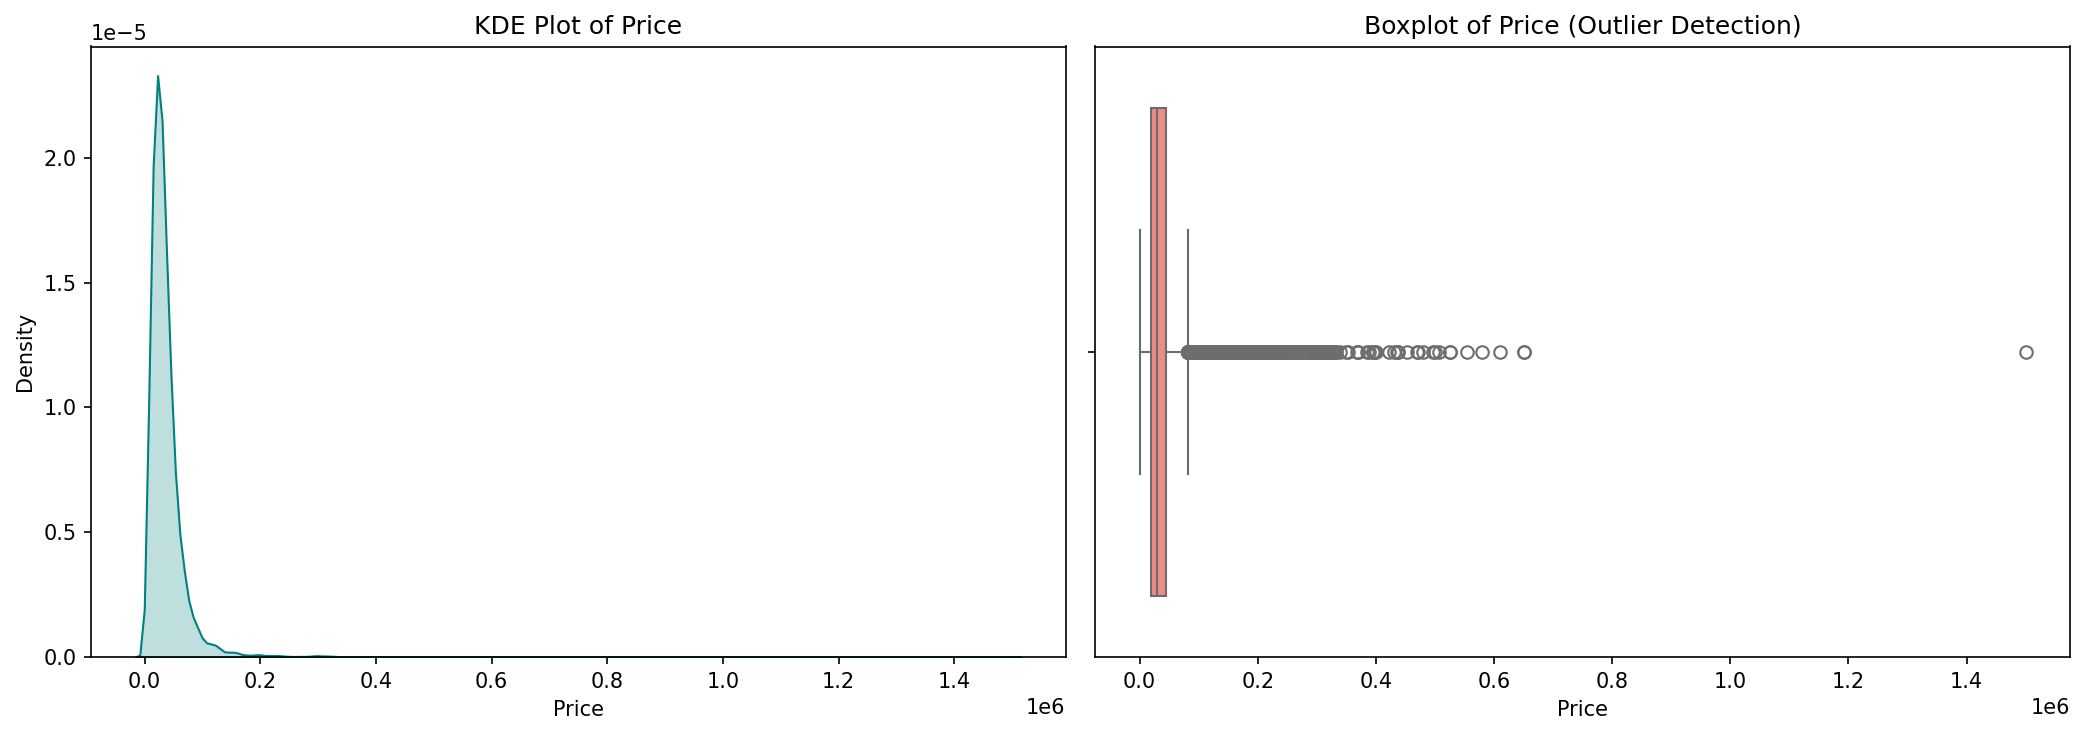

In [153]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# KDE plot (Density curve)
sns.kdeplot(data=df_clean, x='Price', ax=axes[0], fill=True, color='teal')
axes[0].set_title('KDE Plot of Price', fontsize=12)
axes[0].set_xlabel('Price')

# Boxplot (Shows IQR and outlier dots)
sns.boxplot(data=df_clean, x='Price', ax=axes[1], color='salmon')
axes[1].set_title('Boxplot of Price (Outlier Detection)', fontsize=12)
axes[1].set_xlabel('Price')

plt.tight_layout()
plt.show()

In [154]:
print(df["Price"].sort_values().head(20))

12         88.0
1052      900.0
7882     1200.0
1025     1895.0
9174     1895.0
16107    2050.0
1397     2500.0
13253    2500.0
4190     2650.0
11014    2995.0
7603     2995.0
13305    2995.0
6309     2995.0
4031     2995.0
1306     2995.0
2626     2999.0
136      2999.0
6261     2999.0
4072     2999.0
4325     2999.0
Name: Price, dtype: float64


In [155]:
df_clean = df_clean[df_clean['Price'] >= 2500]

In [156]:
q1 = df_clean['Price'].quantile(0.25)
q3 = df_clean['Price'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
df_clean = df_clean[(df_clean['Price'] >= lower_bound) & (df_clean['Price'] <= upper_bound)]

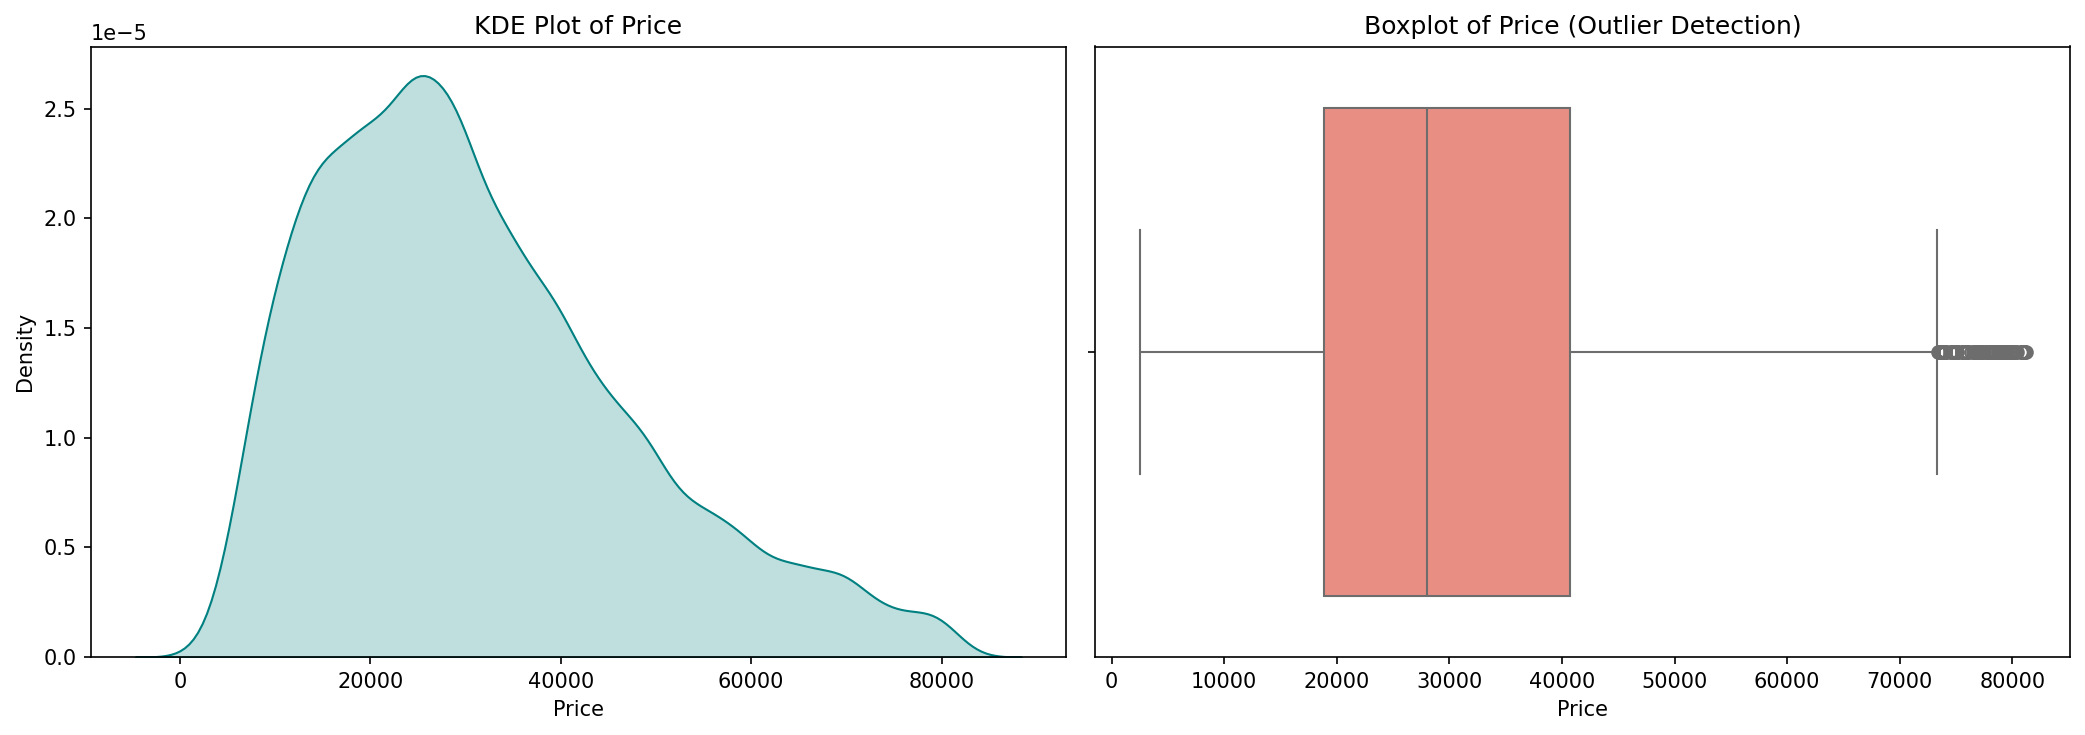

In [157]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# KDE plot (Density curve)
sns.kdeplot(data=df_clean, x='Price', ax=axes[0], fill=True, color='teal')
axes[0].set_title('KDE Plot of Price', fontsize=12)
axes[0].set_xlabel('Price')

# Boxplot (Shows IQR and outlier dots)
sns.boxplot(data=df_clean, x='Price', ax=axes[1], color='salmon')
axes[1].set_title('Boxplot of Price (Outlier Detection)', fontsize=12)
axes[1].set_xlabel('Price')

plt.tight_layout()
plt.show()

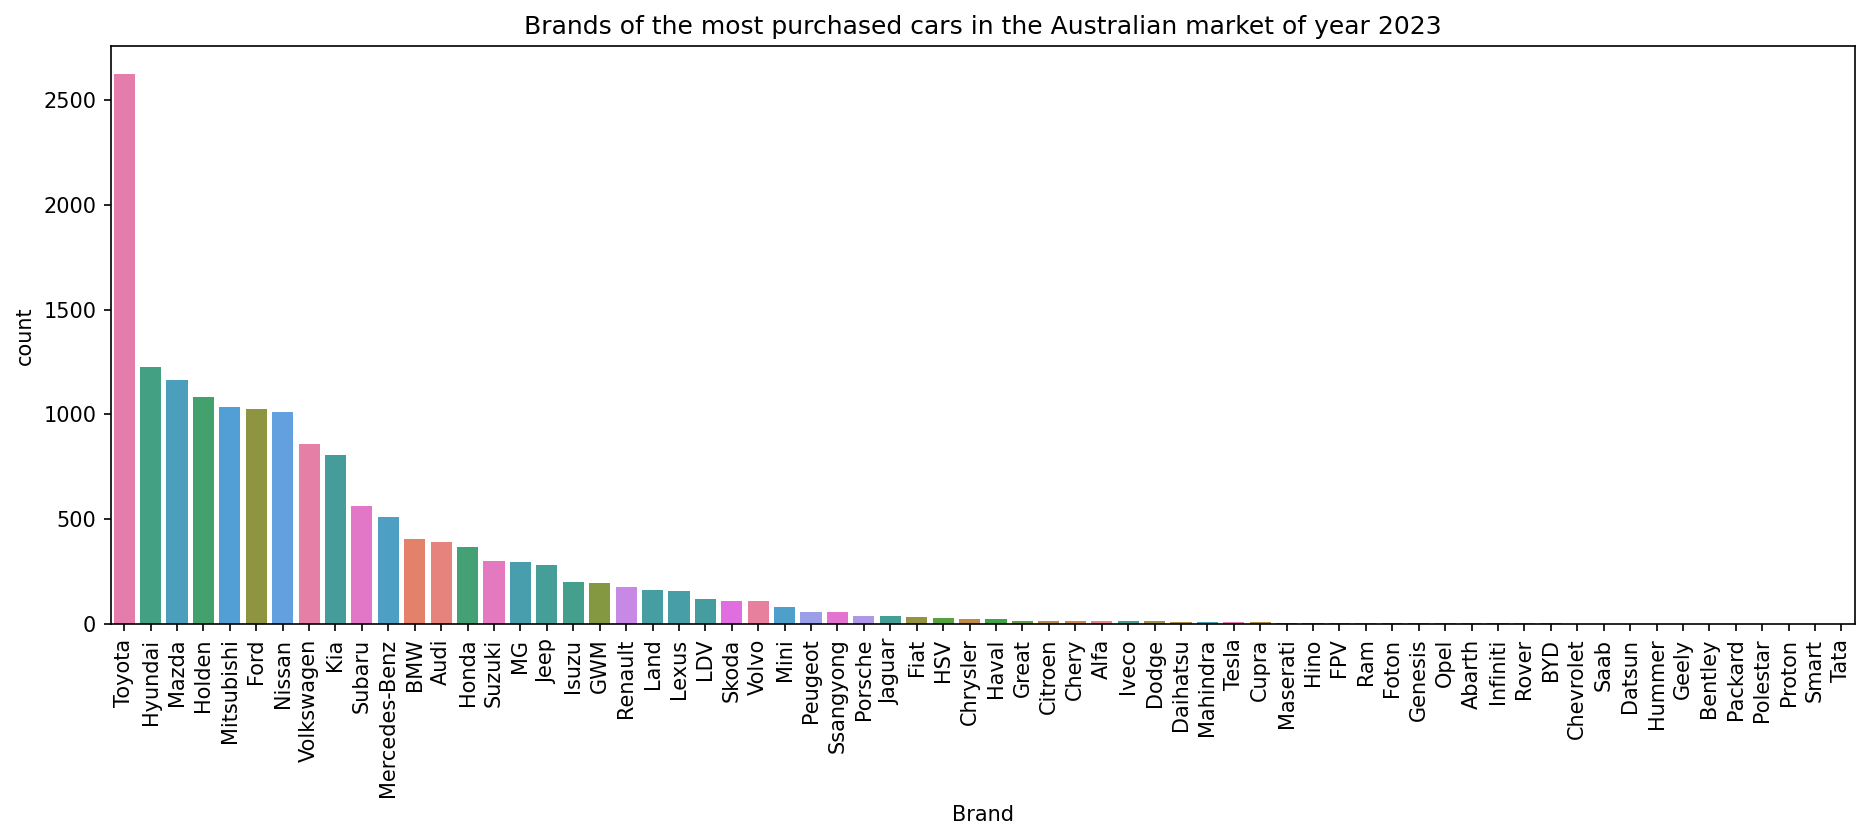

In [158]:
plt.figure(figsize=(15,5),dpi=150)
sns.countplot(data=df_clean, x='Brand',hue='Brand',order=df_clean['Brand'].value_counts().index)
plt.xticks(rotation=90)
plt.title('Brands of the most purchased cars in the Australian market of year 2023');

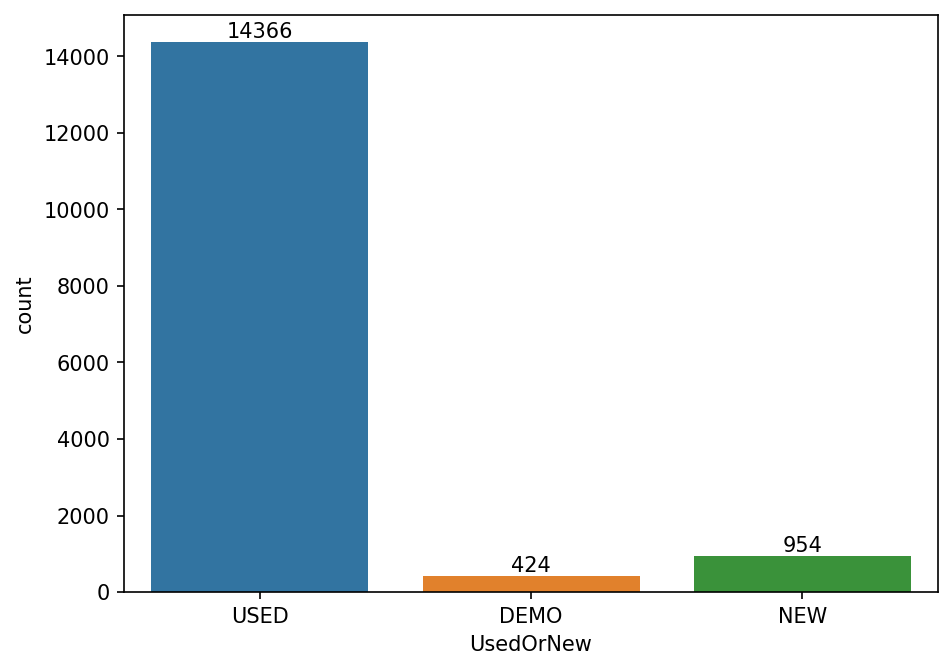

In [159]:
plt.figure(figsize=(7,5),dpi=150)
ax = sns.countplot(data=df_clean, x='UsedOrNew', hue='UsedOrNew')
for i in ax.containers:
    ax.bar_label(i,)


([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'Premium'),
  Text(1, 0, 'Unleaded'),
  Text(2, 0, 'Diesel'),
  Text(3, 0, 'Hybrid'),
  Text(4, 0, 'Leaded'),
  Text(5, 0, 'Electric'),
  Text(6, 0, 'LPG'),
  Text(7, 0, 'Other')])

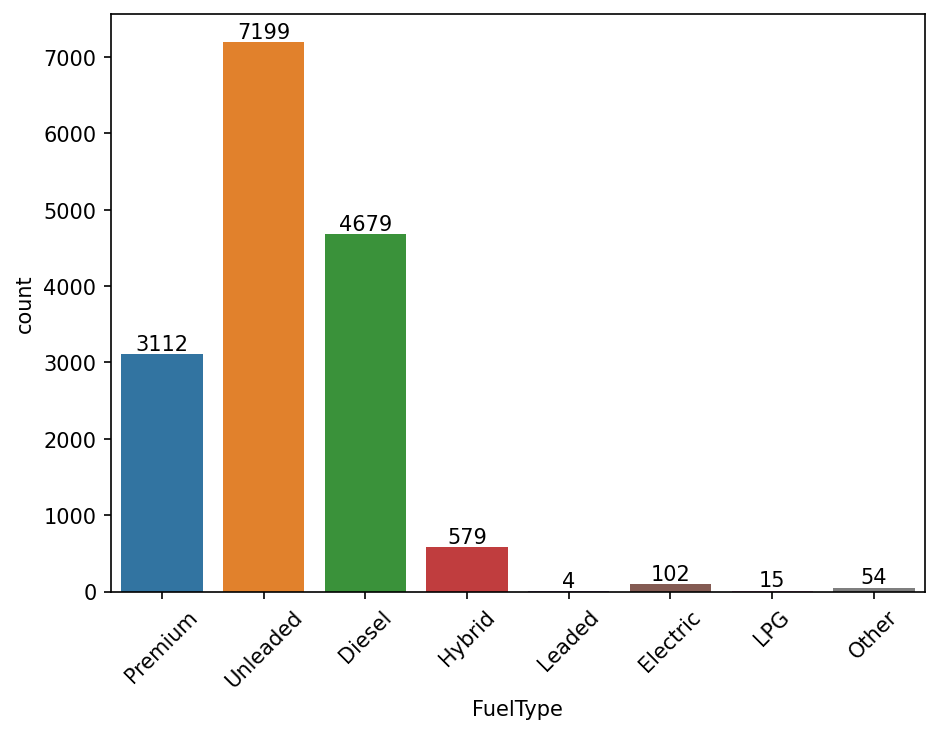

In [160]:
plt.figure(figsize=(7,5),dpi=150)
ax = sns.countplot(data=df_clean, x='FuelType', hue='FuelType')
for i in ax.containers:
    ax.bar_label(i,)


plt.xticks(rotation=45)

In [161]:
fuel_mapping = {'Leaded': 'Other', 'LPG': 'Other'}

df_clean['FuelType'] = df_clean['FuelType'].replace(fuel_mapping)

print(df_clean['FuelType'].value_counts())

FuelType
Unleaded    7199
Diesel      4679
Premium     3112
Hybrid       579
Electric     102
Other         73
Name: count, dtype: int64


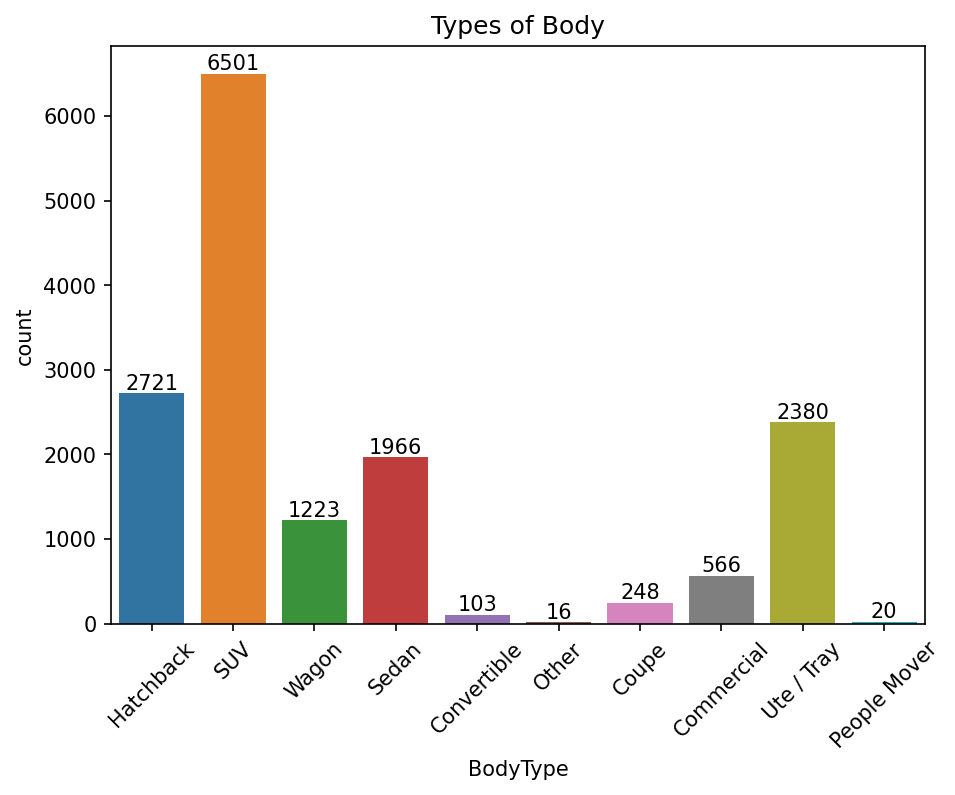

In [162]:
plt.figure(figsize=(7,5),dpi=150)
ax = sns.countplot(data=df_clean, x='BodyType',hue='BodyType')
for i in ax.containers:
    ax.bar_label(i,)

plt.xticks(rotation=45)
plt.title('Types of Body');

In [163]:
# Define mapping for infrequent body types you want to group into 'Other'
body_mapping = {
    'Convertible': 'Other',
    'People Mover': 'Other',
    # Add any other body types you want to group here, e.g.:
    # 'Coupe': 'Other'
}

df['BodyType'] = df['BodyType'].replace(body_mapping)

# Verify the updated counts
print(df['BodyType'].value_counts())

BodyType
SUV           6929
Hatchback     2733
Ute / Tray    2512
Sedan         2070
Wagon         1273
Commercial     625
Coupe          352
Other          187
Name: count, dtype: int64


([0, 1, 2, 3, 4],
 [Text(0, 0, 'Front'),
  Text(1, 0, 'Other'),
  Text(2, 0, 'AWD'),
  Text(3, 0, 'Rear'),
  Text(4, 0, '4WD')])

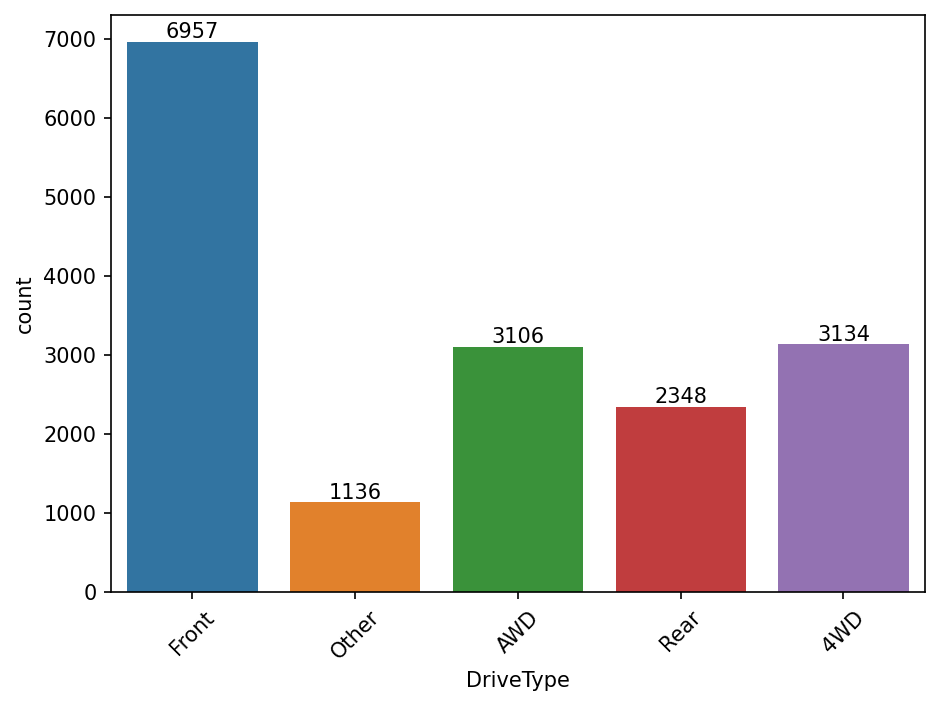

In [164]:
plt.figure(figsize=(7,5),dpi=150)
ax = sns.countplot(data=df, x='DriveType', hue='DriveType')
for i in ax.containers:
    ax.bar_label(i,)


plt.xticks(rotation=45)

([0, 1, 2],
 [Text(0, 0, 'Manual'), Text(1, 0, 'Automatic'), Text(2, 0, 'Unknown')])

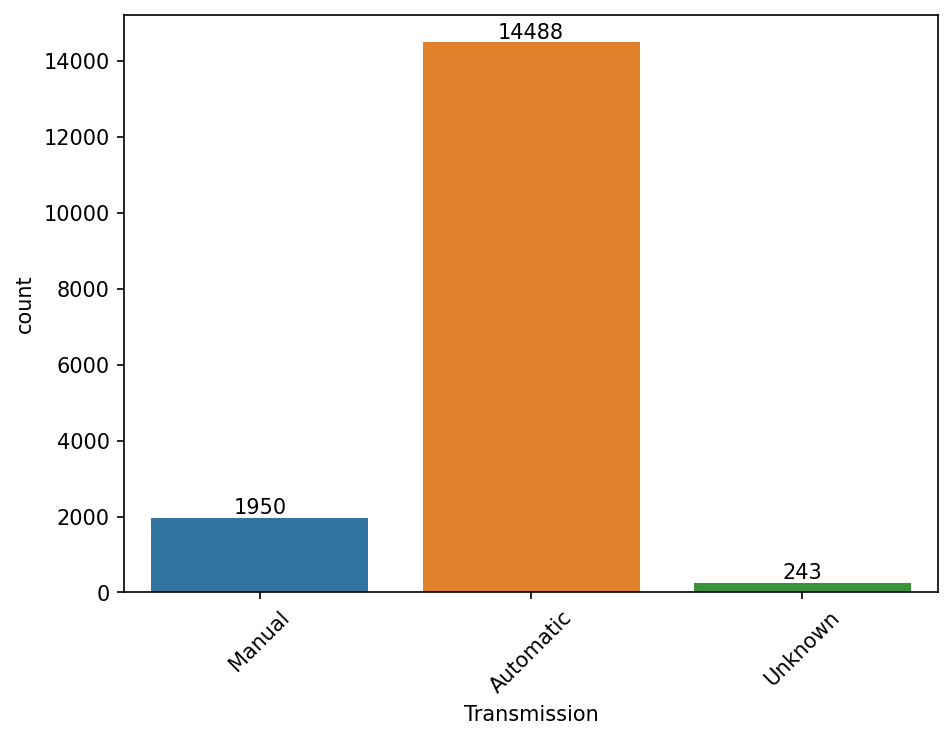

In [165]:
plt.figure(figsize=(7,5),dpi=150)
ax = sns.countplot(data=df, x='Transmission', hue='Transmission')
for i in ax.containers:
    ax.bar_label(i,)


plt.xticks(rotation=45)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'Black'),
  Text(1, 0, 'Grey'),
  Text(2, 0, 'Unknown'),
  Text(3, 0, 'Red'),
  Text(4, 0, 'White'),
  Text(5, 0, 'Blue'),
  Text(6, 0, 'Cream'),
  Text(7, 0, 'Silver'),
  Text(8, 0, 'Green'),
  Text(9, 0, 'Brown'),
  Text(10, 0, 'Gold'),
  Text(11, 0, 'Yellow'),
  Text(12, 0, 'Orange'),
  Text(13, 0, 'Bronze'),
  Text(14, 0, 'Purple'),
  Text(15, 0, 'Other'),
  Text(16, 0, 'Turquoise'),
  Text(17, 0, 'Beige'),
  Text(18, 0, 'Burgundy'),
  Text(19, 0, 'Pink')])

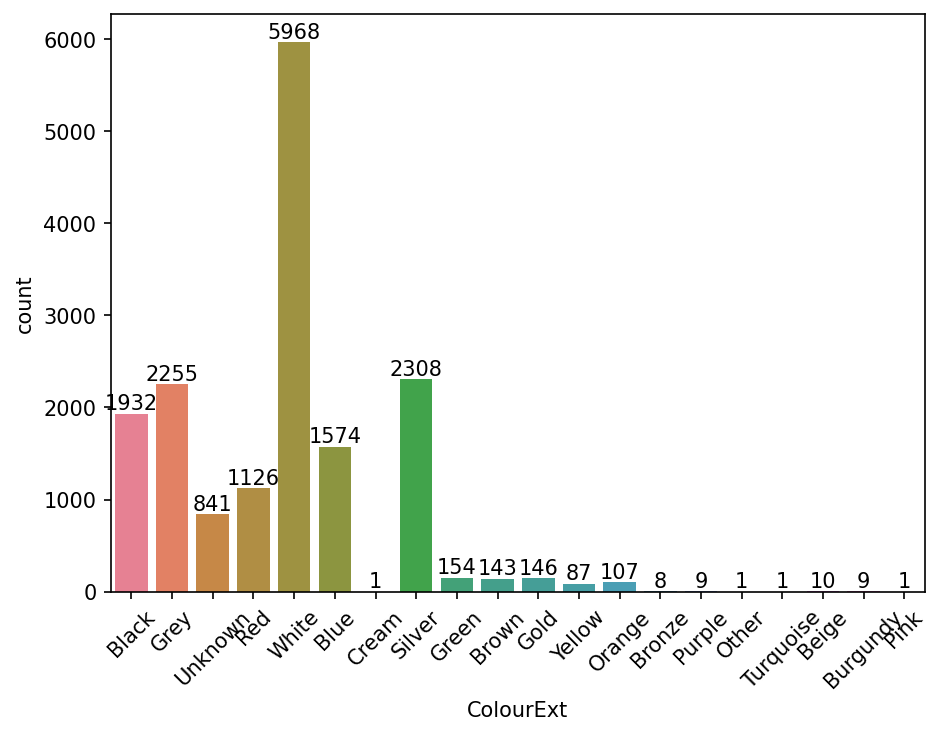

In [166]:
plt.figure(figsize=(7,5),dpi=150)
ax = sns.countplot(data=df, x='ColourExt', hue='ColourExt')
for i in ax.containers:
    ax.bar_label(i,)


plt.xticks(rotation=45)

In [167]:
# Dynamically group any color with fewer than 150 occurrences into 'Rare'
color_counts = df_clean['ColourExt'].value_counts()
rare_colors = color_counts[color_counts < 150].index

df_clean['ColourExt'] = df_clean['ColourExt'].replace(rare_colors, 'Rare')

# Verify the updated counts
print(df_clean['ColourExt'].value_counts())

ColourExt
White      5722
Silver     2236
Grey       2120
Black      1771
Blue       1509
Red        1101
Rare        643
Unknown     642
Name: count, dtype: int64


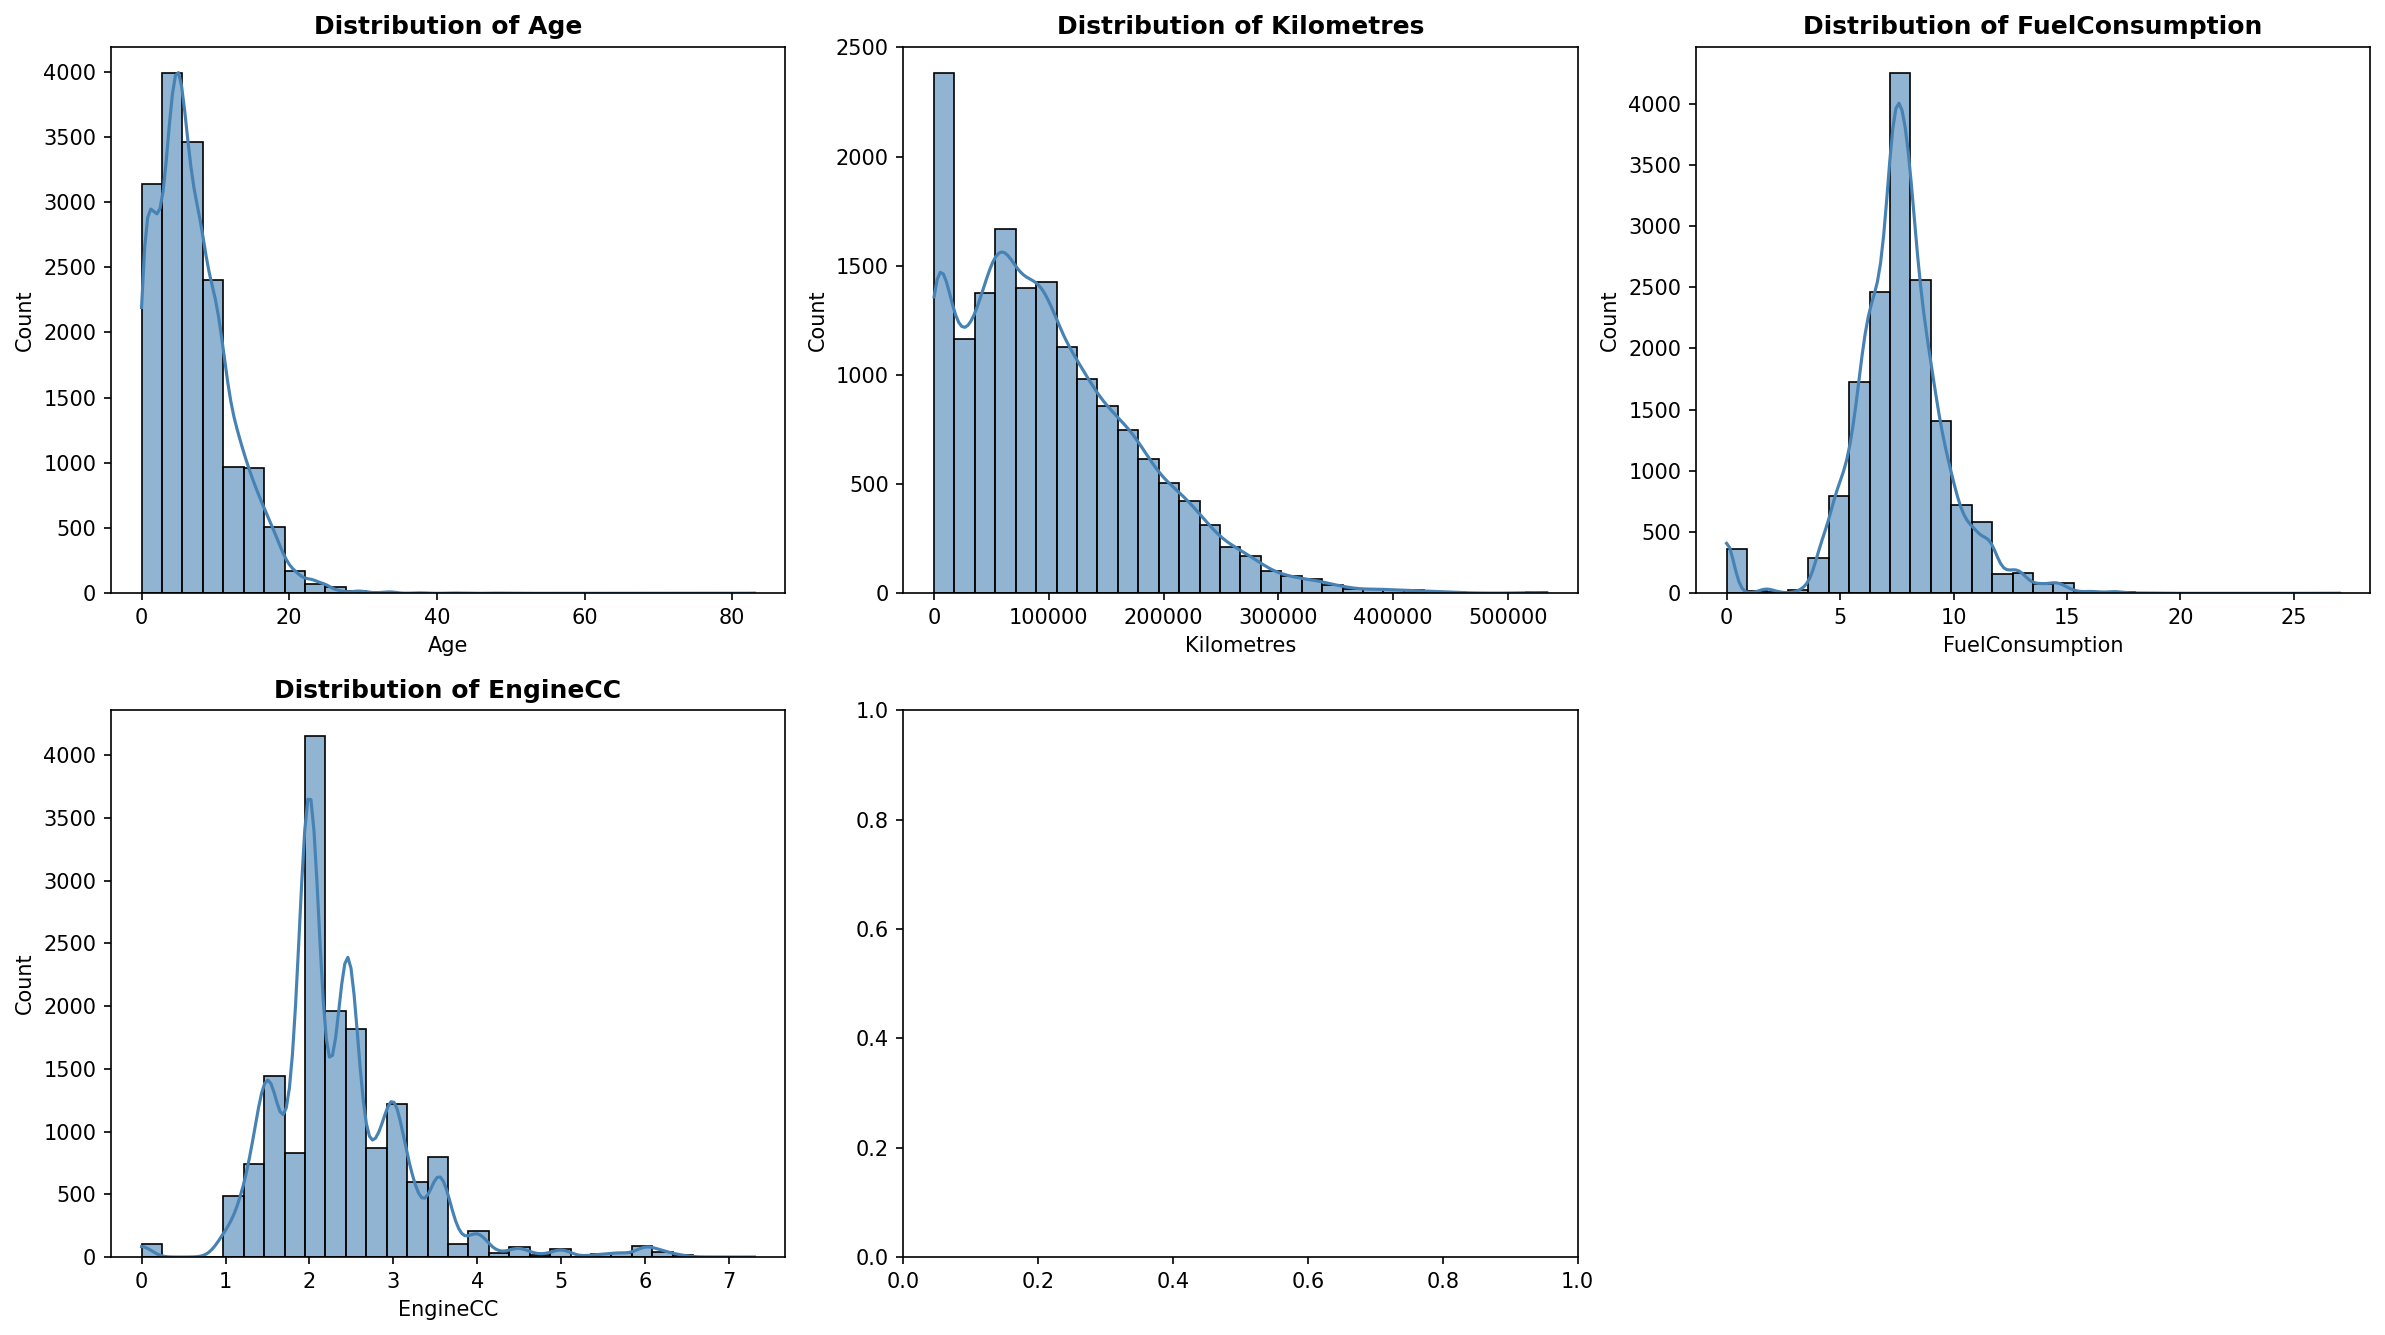

In [168]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=150)
axes = axes.flatten()
num_cols_eda = ['Age', 'Kilometres', 'FuelConsumption', 'EngineCC']

for i, col in enumerate(num_cols_eda):
    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        ax=axes[i],
        color='steelblue',
        bins=30,
        edgecolor='black',
        alpha=0.6
    )
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

# Hide the unused 6th subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

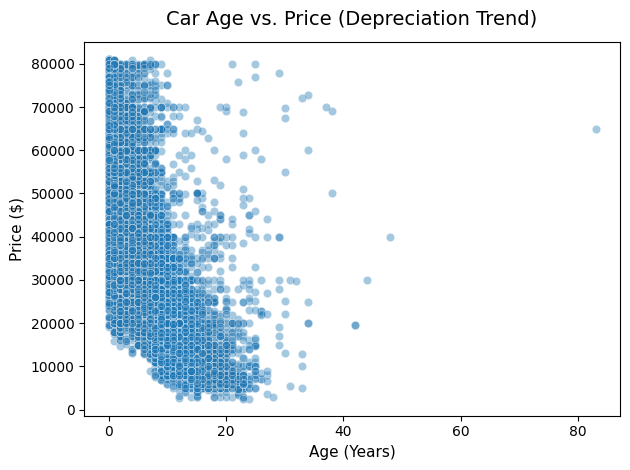

In [169]:
sns.scatterplot(data=df_clean,x='Age',y='Price',alpha=0.4)

plt.title('Car Age vs. Price (Depreciation Trend)', fontsize=14, pad=12)
plt.xlabel('Age (Years)', fontsize=11)
plt.ylabel('Price ($)', fontsize=11)

plt.tight_layout()
plt.show()

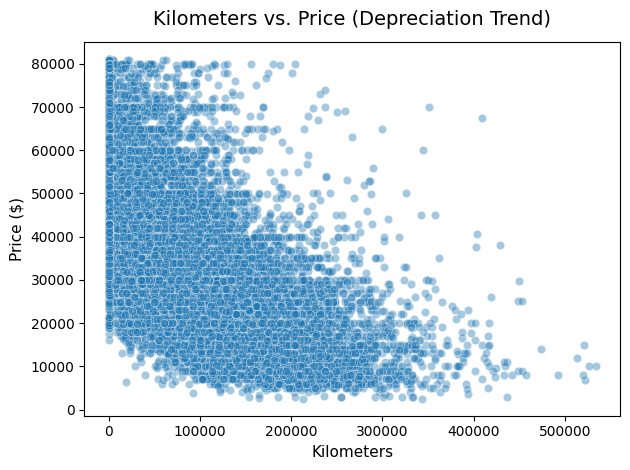

In [170]:
sns.scatterplot(data=df_clean,x='Kilometres',y='Price',alpha=0.4)

plt.title('Kilometers vs. Price (Depreciation Trend)', fontsize=14, pad=12)
plt.xlabel('Kilometers', fontsize=11)
plt.ylabel('Price ($)', fontsize=11)

plt.tight_layout()
plt.show()

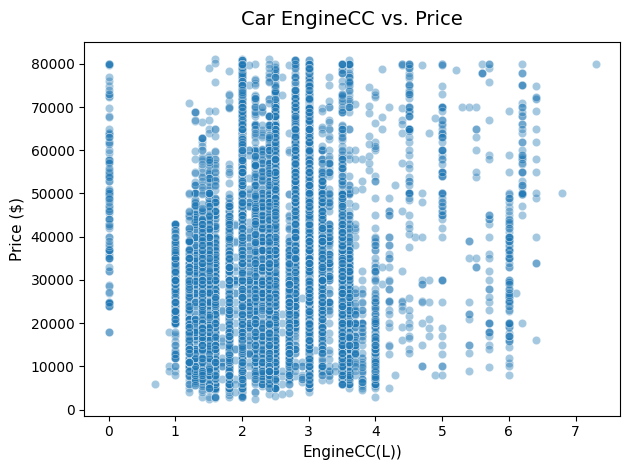

In [171]:
sns.scatterplot(data=df_clean,x='EngineCC',y='Price',alpha=0.4)

plt.title('Car EngineCC vs. Price', fontsize=14, pad=12)
plt.xlabel('EngineCC(L))', fontsize=11)
plt.ylabel('Price ($)', fontsize=11)

plt.tight_layout()
plt.show()

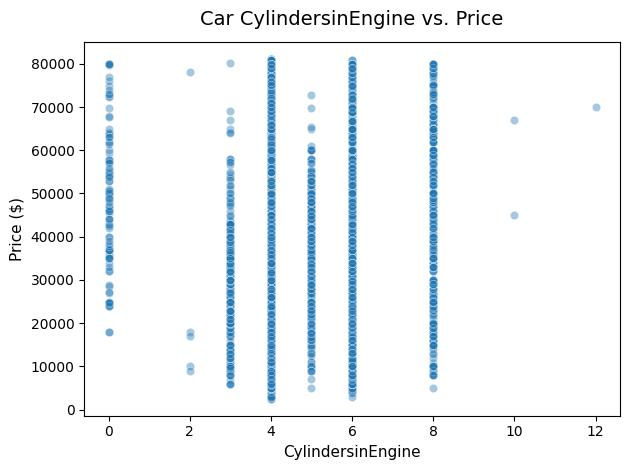

In [172]:
sns.scatterplot(data=df_clean,x='CylindersinEngine',y='Price',alpha=0.4)

plt.title('Car CylindersinEngine vs. Price', fontsize=14, pad=12)
plt.xlabel('CylindersinEngine', fontsize=11)
plt.ylabel('Price ($)', fontsize=11)

plt.tight_layout()
plt.show()

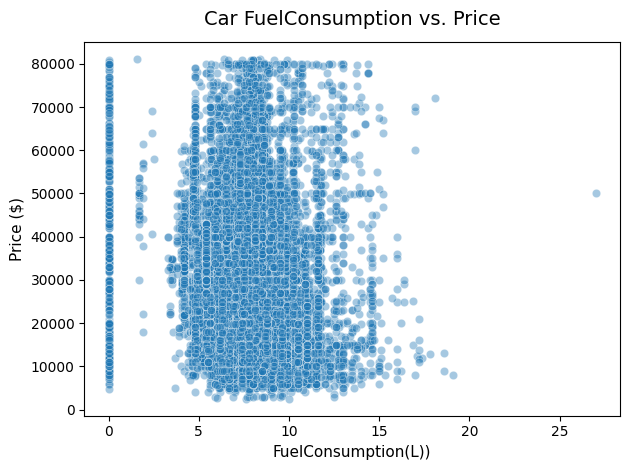

In [173]:
sns.scatterplot(data=df_clean,x='FuelConsumption',y='Price',alpha=0.4)

plt.title('Car FuelConsumption vs. Price', fontsize=14, pad=12)
plt.xlabel('FuelConsumption(L))', fontsize=11)
plt.ylabel('Price ($)', fontsize=11)

plt.tight_layout()
plt.show()

In [174]:
# Check which FuelTypes have a FuelConsumption of 0
zero_fuel_breakdown = df[df['FuelConsumption'] == 0]['FuelType'].value_counts()
print(zero_fuel_breakdown)

FuelType
Diesel      262
Electric    136
Unleaded     67
Premium      19
Leaded        2
Other         1
Hybrid        1
Name: count, dtype: int64


In [175]:
df_clean['Age'].quantile(0.99)

np.float64(22.0)

In [176]:
df_clean = df_clean[df_clean['Age'] <= 22]

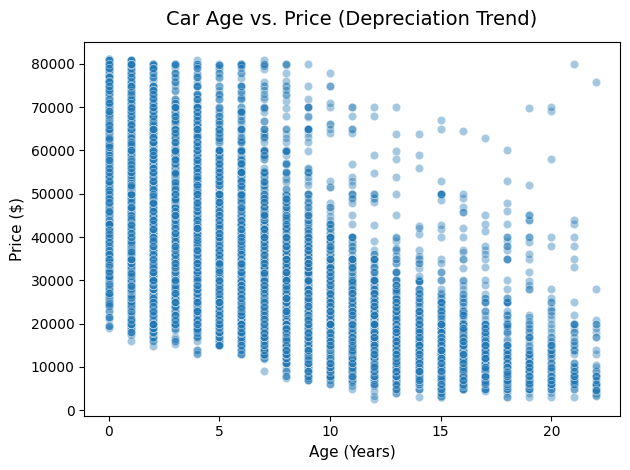

In [177]:
sns.scatterplot(data=df_clean,x='Age',y='Price',alpha=0.4)

plt.title('Car Age vs. Price (Depreciation Trend)', fontsize=14, pad=12)
plt.xlabel('Age (Years)', fontsize=11)
plt.ylabel('Price ($)', fontsize=11)

plt.tight_layout()
plt.show()

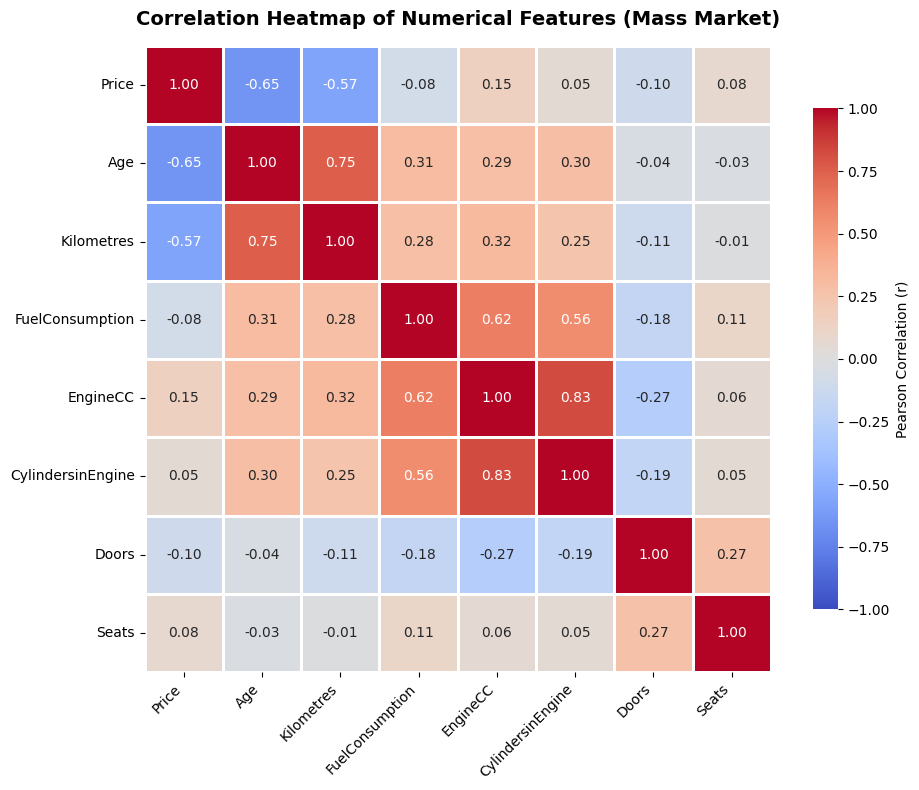

In [178]:
numeric_cols = [
    'Price',
    'Age',
    'Kilometres',
    'FuelConsumption',
    'EngineCC',
    'CylindersinEngine',
    'Doors',
    'Seats',
]
valid_cols = [col for col in numeric_cols if col in df_clean.columns]

# 2. Compute Pearson correlation matrix
corr_matrix = df_clean[valid_cols].corr()

# 3. Create a mask for the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 4. Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1.0,
    vmax=1.0,
    center=0,
    square=True,
    linewidths=0.75,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation (r)'},
)

plt.title(
    'Correlation Heatmap of Numerical Features (Mass Market)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [179]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


X = df_clean.drop(columns=['Price'])
y = df_clean['Price']

cat_cols = ['UsedOrNew','Transmission','DriveType','FuelType','BodyType','State','ColourExt','Brand']

num_cols = ['FuelConsumption','Kilometres','CylindersinEngine','Doors','Seats','EngineCC','Age']


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ],
    remainder='drop'
)


X_encoded = preprocessor.fit_transform(X)

encoded_cols = preprocessor.get_feature_names_out()
X_encoded_df_clean = pd.DataFrame(X_encoded, columns=encoded_cols, index=df_clean.index)

In [180]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X_encoded_df_clean, y, test_size = 0.20, random_state = 42)

In [181]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)

ols = sm.OLS(y_train, X_train_const).fit()
y_pred_ols = ols.predict(X_test_const)


/tmp/ipykernel_1471/2541418851.py:7: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols = sm.OLS(y_train, X_train_const).fit()


In [182]:
n = len(y_test)
p = X_test_const.shape[1] - 1

# Calculate metrics
r2 = r2_score(y_test, y_pred_ols)
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
mae = mean_absolute_error(y_test, y_pred_ols)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_ols))

# Create the evaluation table
eval_df = pd.DataFrame({
    'Model': ['OLS Regression'],
    'R2': [r2],
    'Adj R2': [adj_r2],
    'MAE': [mae],
    'RMSE': [rmse]
}).set_index('Model')

print(eval_df)

                      R2    Adj R2          MAE         RMSE
Model                                                       
OLS Regression  0.780716  0.773149  5674.553832  7607.574751


<>:13: SyntaxWarning: invalid escape sequence '\h'
<>:14: SyntaxWarning: invalid escape sequence '\h'
<>:13: SyntaxWarning: invalid escape sequence '\h'
<>:14: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_1471/2848582391.py:13: SyntaxWarning: invalid escape sequence '\h'
  plt.xlabel('Fitted Values ($\hat{y}$)')
/tmp/ipykernel_1471/2848582391.py:14: SyntaxWarning: invalid escape sequence '\h'
  plt.ylabel('Residuals ($y - \hat{y}$)')


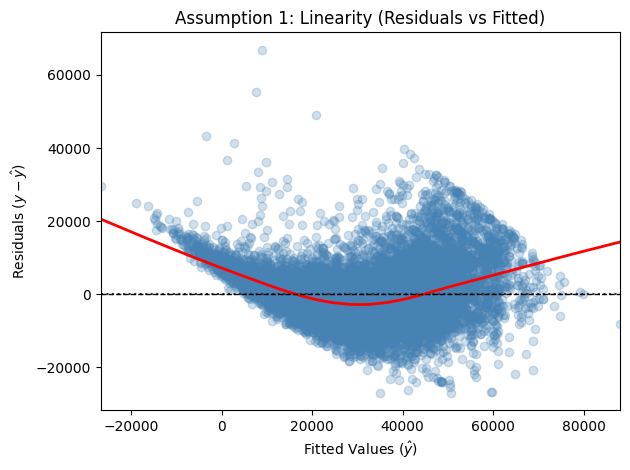

In [183]:
fitted_vals = ols.fittedvalues
residuals = ols.resid
sns.residplot(
    x=fitted_vals,
    y=residuals,
    lowess=True,
    color='steelblue',
    scatter_kws={'alpha': 0.25},
    line_kws={'color': 'red', 'lw': 2}
)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('Linearity (Residuals vs Fitted)', fontsize=12)
plt.xlabel('Fitted Values ($\hat{y}$)')
plt.ylabel('Residuals ($y - \hat{y}$)')
plt.tight_layout()
plt.show()

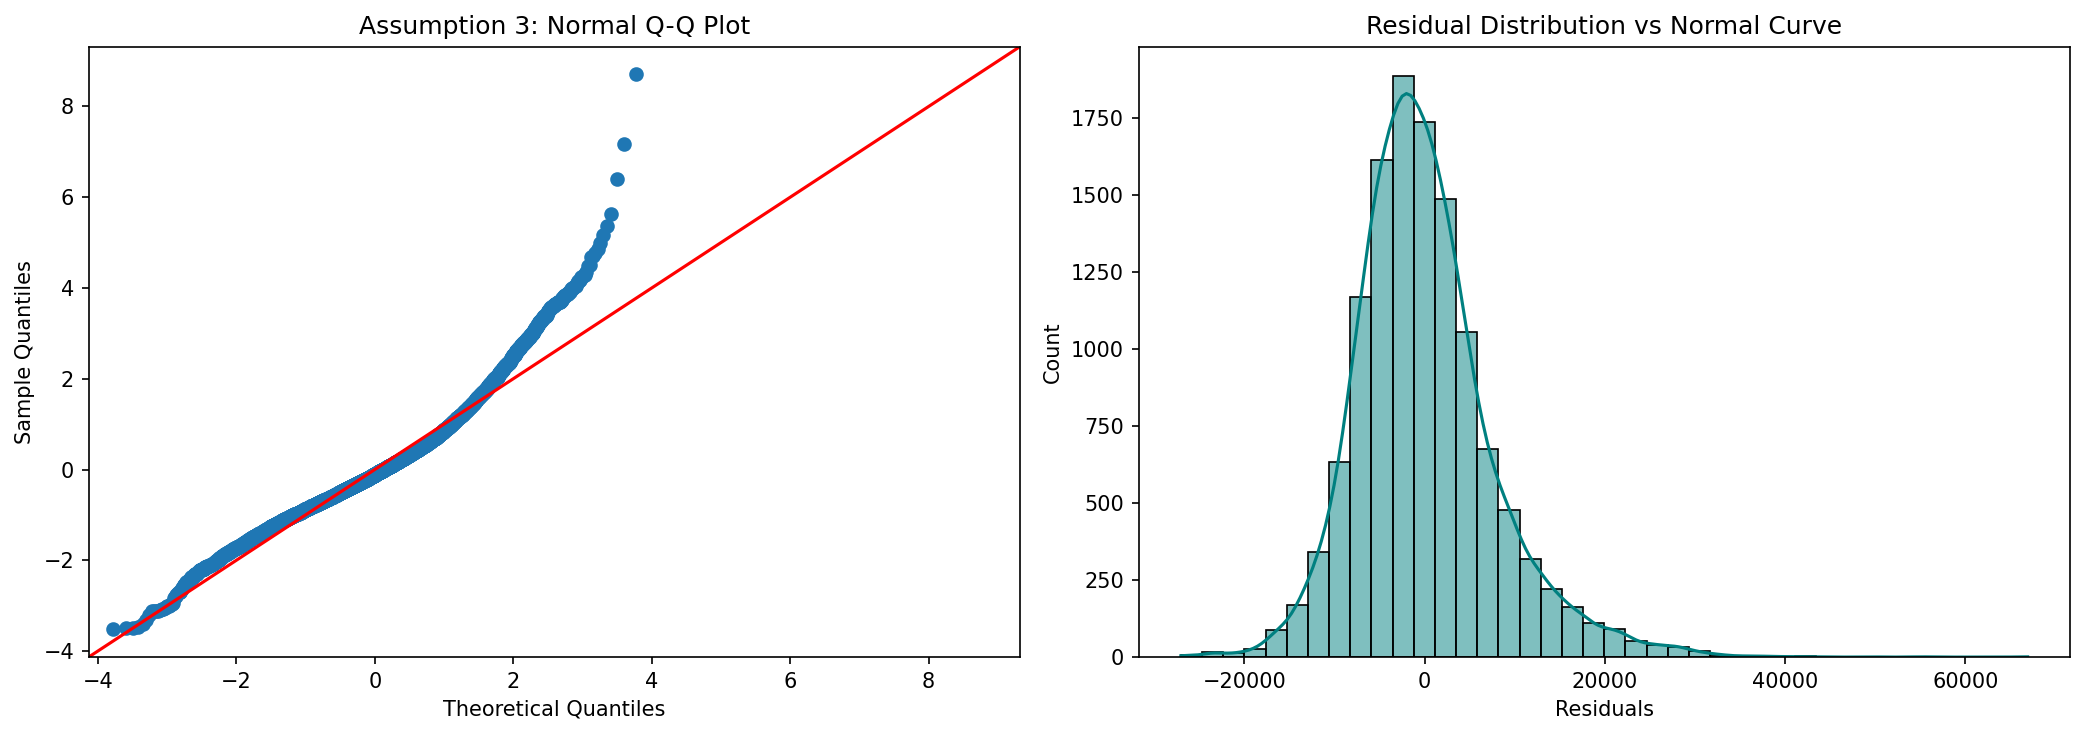

In [184]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Q-Q Plot
sm.qqplot(residuals, line='45', fit=True, ax=axes[0])
axes[0].set_title('Normal Q-Q Plot')

# Histogram + KDE of Residuals
sns.histplot(residuals, kde=True, ax=axes[1], color='teal', bins=40)
axes[1].set_title('Residual Distribution vs Normal Curve')
axes[1].set_xlabel('Residuals')

plt.tight_layout()
plt.show()

In [207]:
import pandas as pd
import statsmodels.stats.api as sms
from scipy.stats import shapiro
from statsmodels.stats.stattools import durbin_watson

sw_stat, sw_pval = shapiro(residuals)
bp_stat, bp_pval, _, _ = sms.het_breuschpagan(residuals, X_train_const)
dw_stat = durbin_watson(residuals)

data = {
    'Test': [
        'Shapiro-Wilk (Normality)',
        'Breusch-Pagan (Homoskedasticity)',
        'Durbin-Watson (Autocorrelation)'
    ],
    'Statistic': [sw_stat, bp_stat, dw_stat],
    'p-value': [sw_pval, bp_pval, 'N/A']
}

# 3. Create and print the DataFrame
diagnostic_df = pd.DataFrame(data).set_index('Test')

print(diagnostic_df)

                                    Statistic p-value
Test                                                 
Shapiro-Wilk (Normality)             0.959250     0.0
Breusch-Pagan (Homoskedasticity)  1342.642115     0.0
Durbin-Watson (Autocorrelation)      1.964401     N/A


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:1217: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y, x).fit()


In [187]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select only scaled numeric columns
numeric_feature_names = [col for col in X_encoded_df_clean.columns if col.startswith('num__')]
X_numeric = X_encoded_df_clean[numeric_feature_names].copy()
X_numeric = sm.add_constant(X_numeric)

vif_data = pd.DataFrame()
vif_data['Feature'] = [col.replace('num__', '') for col in X_numeric.columns]
vif_data['VIF'] = [variance_inflation_factor(X_numeric.values, i) for i in range(X_numeric.shape[1])]

print("=== Variance Inflation Factor (Numeric Features) ===")
print(vif_data.sort_values(by='VIF', ascending=False).to_string(index=False))

=== Variance Inflation Factor (Numeric Features) ===
          Feature      VIF
         EngineCC 3.837933
CylindersinEngine 3.301952
              Age 2.477950
       Kilometres 2.459731
  FuelConsumption 1.713196
            Doors 1.205125
            Seats 1.119848
            const 1.000000


### OLS Assumption Diagnostics: Results & Interpretation

Based on the diagnostic tests, the model passes the assumption of independent errors but violates the assumptions of normality and homoskedasticity.

#### 1. Linearity
* **Visual Evidence:** The red trend line forms a distinct "U" shape (parabola) instead of lying flat along the dashed zero line.
* **Interpretation:** **Failed.** The relationship between your independent variables and the target variable is non-linear. Because your OLS model is forcing a straight line through curved data, it is systematically under-predicting at the extremes (low and high fitted values) and over-predicting in the middle.

#### 2. Homoskedasticity (Constant Variance)
* **Visual Evidence:** The spread of the blue dots (residuals) is not consistent. They form a "funnel" shape, clustering tighter on the left side and spreading out massively on the right side as fitted values increase.
* **Test:** Breusch-Pagan
* **Result:** Statistic = 1342.64 | p-value = 0.000
* **Interpretation:** **Failed.** Since the p-value < 0.05, we reject the null hypothesis. The model suffers from **heteroskedasticity**, meaning the error variance changes across different values of the predictors.

#### 3. Multicollinearity
* **Overall Verdict: Passed.** Every feature has a VIF below the strict cutoff of 5.0. This means none of your independent variables are highly perfectly predicted by the others, and the standard errors of your coefficients are not being artificially inflated by multicollinearity.
* **The Highest Values (`EngineCC` & `CylindersinEngine`):**
  At 3.84 and 3.30, these two have the highest moderate correlation. This makes logical real-world sense (cars with larger engine capacities typically have more cylinders). However, because they are still under 5, the model can safely distinguish the independent effect of each variable.
* **The Rest (`Age`, `Kilometres`, `FuelConsumption`, `Doors`, `Seats`):**
  Scores between 1.1 and 2.5 indicate very low to mild correlation. They bring highly independent information to the model.

#### 4. Normality of Residuals
* **Test:** Shapiro-Wilk
* **Result:** Statistic = 0.9593 | p-value = 0.000
* **Interpretation:** **Failed.** Since the p-value < 0.05, we reject the null hypothesis. The residuals are **not normally distributed**.

#### 5. Autocorrelation (Independence of Errors)
* **Test:** Durbin-Watson
* **Result:** Statistic = 1.964
* **Interpretation:** **Passed.** The statistic is very close to 2.0 (the ideal value), indicating there is **no significant first-order autocorrelation** in the residuals. The observations are independent.



In [189]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

ols_log = sm.OLS(y_train_log, X_train_const).fit()
y_pred_log = ols_log.predict(X_test_const)

/tmp/ipykernel_1471/1587240379.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_log = sm.OLS(y_train_log, X_train_const).fit()


In [203]:
n = len(y_test)
p = X_test_const.shape[1] - 1

r2 = r2_score(y_test, np.expm1(y_pred_log))
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
mae = mean_absolute_error(y_test, np.expm1(y_pred_log))
rmse = np.sqrt(mean_squared_error(y_test, np.expm1(y_pred_log)))

eval_df = pd.DataFrame({
    'Model': ['OLS Regression'],
    'R2': [r2],
    'Adj R2': [adj_r2],
    'MAE': [mae],
    'RMSE': [rmse]
}).set_index('Model')

print(eval_df)

                      R2    Adj R2          MAE         RMSE
Model                                                       
OLS Regression  0.807171  0.800517  4917.230963  7133.923009


<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1471/4228370287.py:17: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_xlabel('Fitted Values ($\log(Price)$)')


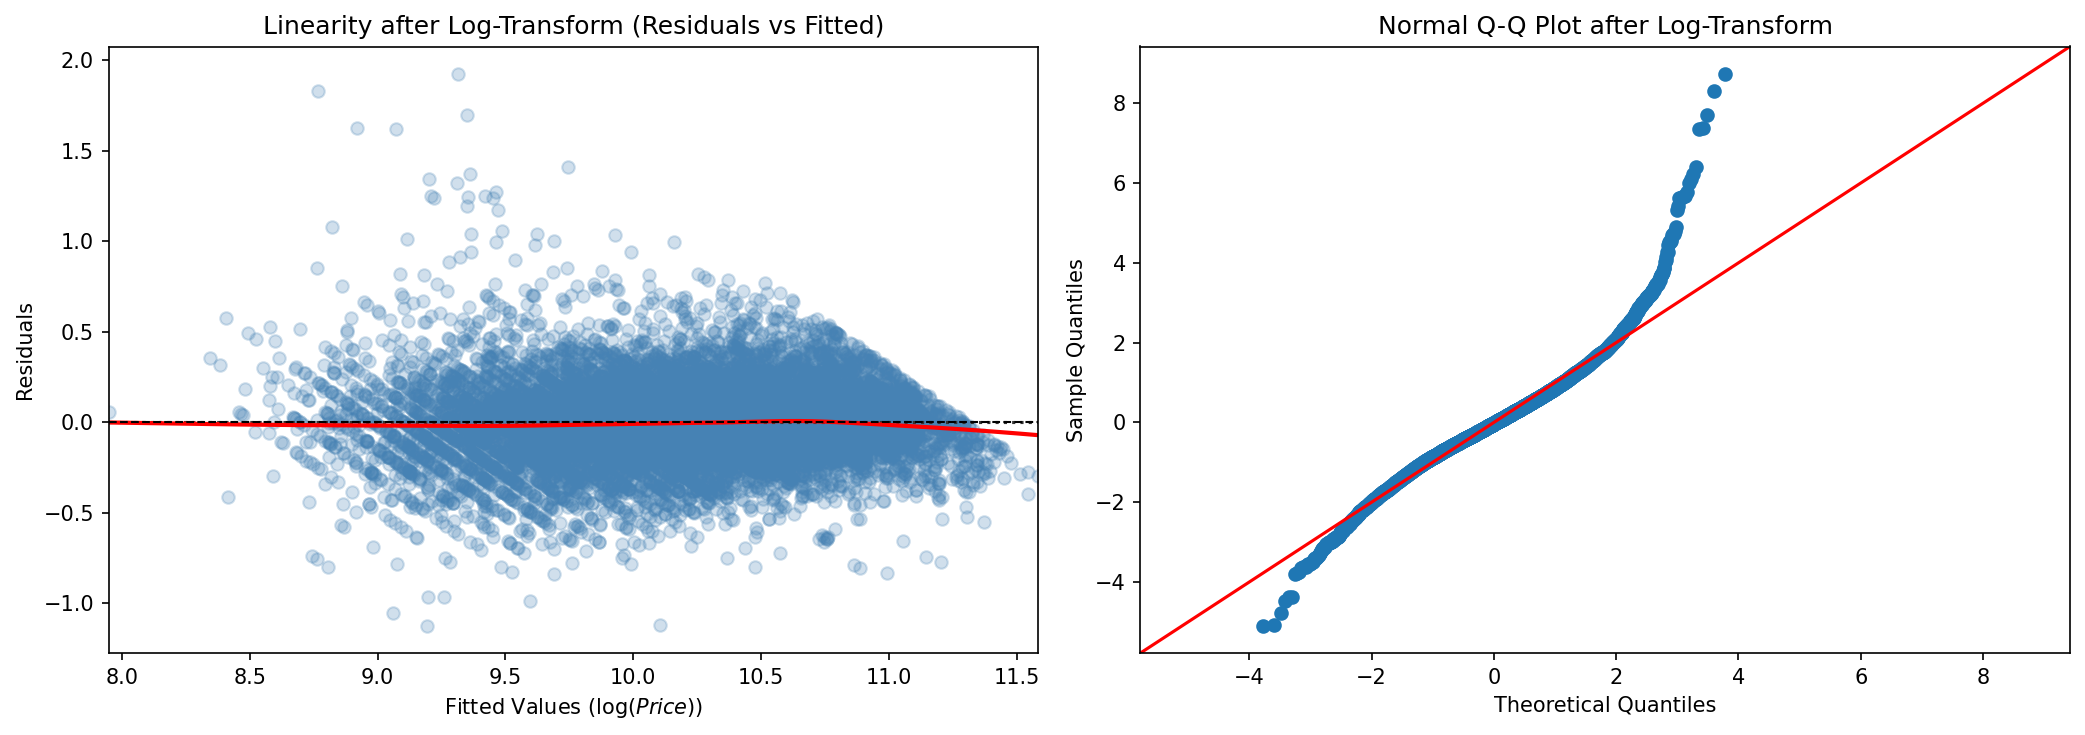

In [191]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

fitted_vals_log = ols_log.fittedvalues
residuals_log = ols_log.resid
# Check Linearity
sns.residplot(
    x=fitted_vals_log,
    y=residuals_log,
    lowess=True,
    ax=axes[0],
    color='steelblue',
    scatter_kws={'alpha': 0.25},
    line_kws={'color': 'red', 'lw': 2},
)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set_title('Linearity after Log-Transform (Residuals vs Fitted)')
axes[0].set_xlabel('Fitted Values ($\log(Price)$)')
axes[0].set_ylabel('Residuals')

# Check Normality
sm.qqplot(residuals_log, line='45', fit=True, ax=axes[1])
axes[1].set_title('Normal Q-Q Plot after Log-Transform')

plt.tight_layout()
plt.show()

In [208]:
sw_stat, sw_pval = shapiro(residuals_log)
bp_stat, bp_pval, _, _ = sms.het_breuschpagan(residuals_log, X_train_const)
dw_stat = durbin_watson(residuals_log)

data = {
    'Test': [
        'Shapiro-Wilk (Normality)',
        'Breusch-Pagan (Homoskedasticity)',
        'Durbin-Watson (Autocorrelation)'
    ],
    'Statistic': [sw_stat, bp_stat, dw_stat],
    'p-value': [sw_pval, bp_pval, 'N/A']
}

diagnostic_df = pd.DataFrame(data).set_index('Test')

print(diagnostic_df)

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 12473.
  res = hypotest_fun_out(*samples, **kwds)


                                    Statistic p-value
Test                                                 
Shapiro-Wilk (Normality)             0.969434     0.0
Breusch-Pagan (Homoskedasticity)  1371.879863     0.0
Durbin-Watson (Autocorrelation)      1.964328     N/A


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:1217: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y, x).fit()


### OLS Diagnostic Results: Post Log-Transformation (image_0f0bc2.jpg)

The log-transformation successfully fixed the primary linearity issue, but the model still technically violates the strict statistical assumptions of normality and homoskedasticity.

#### 1. Linearity (Visual Assessment)
* **Visual Evidence:** In the "Linearity after Log-Transform" plot from image_0f0bc2.jpg, the red trend line is now flat and tracks very closely to the dashed zero line. The severe "U" shape seen in the previous model is completely gone.
* **Interpretation:** **Passed/Fixed.** The log-transformation successfully linearized the relationship between the predictors and the target variable.

#### 2. Normality of Residuals
* **Statistical Test:** Shapiro-Wilk (Statistic = 0.9694, p-value = 0.0) -> **Failed.**
* **Visual Evidence:** The "Normal Q-Q Plot after Log-Transform" in image_0f0bc2.jpg shows that while the middle bulk of the data hugs the red diagonal line, the points curve away from the line significantly at both the upper and lower extremes.
* **Interpretation:** The residuals have "heavy tails," meaning there are more extreme outliers than a perfect normal distribution would allow. This deviation at the tails is why the Shapiro-Wilk test continues to fail.

#### 3. Homoskedasticity (Constant Variance)
* **Statistical Test:** Breusch-Pagan (Statistic = 1371.88, p-value = 0.0) -> **Failed.**
* **Visual Evidence:** While the massive funnel shape from the previous iteration is reduced, the spread of the blue dots in the "Residuals vs Fitted" plot still shows uneven density and a slight tapering/boundary effect as fitted values increase.
* **Interpretation:** The variance of the errors is still not perfectly constant across the predicted range, triggering the Breusch-Pagan failure.

#### 4. Autocorrelation (Independence of Errors)
* **Statistical Test:** Durbin-Watson (Statistic = 1.964) -> **Passed.**
* **Interpretation:** The value remains practically at the ideal 2.0 mark. The errors are independent with no autocorrelation.


In [195]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth = 15, min_samples_leaf=5,random_state=42)
dt.fit(X_train,y_train)
y_pred_dt = dt.predict(X_test)

In [196]:
n = len(y_test)
p = X_test_const.shape[1] - 1

r2 = r2_score(y_test, y_pred_dt)
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
mae = mean_absolute_error(y_test, y_pred_dt)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_dt))

eval_df = pd.DataFrame({
    'Model': ['OLS Regression'],
    'R2': [r2],
    'Adj R2': [adj_r2],
    'MAE': [mae],
    'RMSE': [rmse]
}).set_index('Model')

print(eval_df)

                      R2    Adj R2          MAE         RMSE
Model                                                       
OLS Regression  0.804313  0.797561  4901.796612  7186.591866


In [197]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200,  max_depth=20,min_samples_split=5,min_samples_leaf=2,max_features='sqrt',random_state=42,n_jobs=-1)


rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [198]:
n = len(y_test)
p = X_test_const.shape[1] - 1

r2 = r2_score(y_test, y_pred_rf)
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))

eval_df = pd.DataFrame({
    'Model': ['OLS Regression'],
    'R2': [r2],
    'Adj R2': [adj_r2],
    'MAE': [mae],
    'RMSE': [rmse]
}).set_index('Model')

print(eval_df)

                      R2   Adj R2          MAE         RMSE
Model                                                      
OLS Regression  0.855419  0.85043  4283.044486  6177.284404


In [199]:
import xgboost as xgb

xgb_model = xgb.XGBRegressor(random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

In [200]:
n = len(y_test)
p = X_test_const.shape[1] - 1

r2 = r2_score(y_test, y_pred_xgb)
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

eval_df = pd.DataFrame({
    'Model': ['OLS Regression'],
    'R2': [r2],
    'Adj R2': [adj_r2],
    'MAE': [mae],
    'RMSE': [rmse]
}).set_index('Model')

print(eval_df)

                      R2    Adj R2          MAE         RMSE
Model                                                       
OLS Regression  0.892539  0.888831  3686.166996  5325.599922


In [201]:
# Assuming you have predictions from other models like y_pred_rf, y_pred_xgb, etc.
predictions = {
    'Decision Trees': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb
}

results = []
for model_name, y_pred in predictions.items():
    r2 = r2_score(y_test, y_pred)
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        'Model': model_name,
        'R2': round(r2, 4),
        'Adj R2': round(adj_r2, 4),
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4)
    })

eval_df_all = pd.DataFrame(results).set_index('Model')
print(eval_df_all)

                    R2  Adj R2        MAE       RMSE
Model                                               
Decision Trees  0.8043  0.7976  4901.7966  7186.5919
Random Forest   0.8554  0.8504  4283.0445  6177.2844
XGBoost         0.8925  0.8888  3686.1670  5325.5999


/tmp/ipykernel_1471/1170659868.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=agg.values, y=agg.index, palette="viridis")


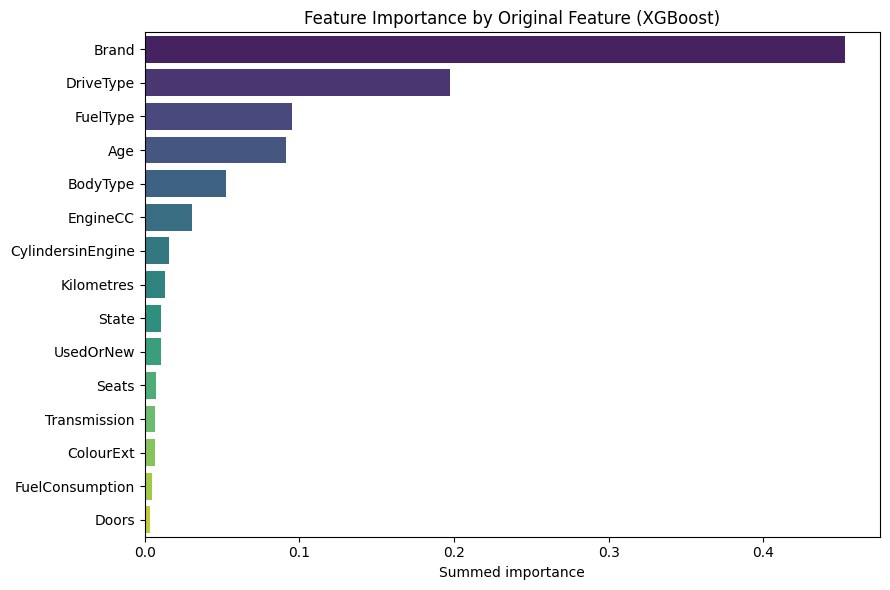

In [202]:
feature_names = preprocessor.get_feature_names_out()
importances = xgb_model.feature_importances_
imp = pd.DataFrame({"feature": feature_names, "importance": importances})

# Map each transformed column back to its original column
cat_cols = ["Brand", "UsedOrNew", "Transmission", "DriveType", "FuelType",
            "BodyType", "Doors", "Seats", "ColourExt", "State"]

def original_name(name):
    name = name.split("__", 1)[-1]
    for c in cat_cols:
        if name.startswith(c + "_"):
            return c
    return name

imp["group"] = imp["feature"].map(original_name)
agg = (imp.groupby("group")["importance"].sum()
          .sort_values(ascending=False))

plt.figure(figsize=(9, 6))
sns.barplot(x=agg.values, y=agg.index, palette="viridis")
plt.title("Feature Importance by Original Feature (XGBoost)")
plt.xlabel("Summed importance")
plt.ylabel("")
plt.tight_layout()
plt.show()